# TFM: predicción de la inflación del IPC con un Temporal Fusion Transformer (TFT)

El TFT usa ** 531 variables de base_tfm.xlsx y, en una segunda versión, además las **variables textuales** de las comunicaciones de bancos centrales (BIS). Con esto se contrastan tres hipótesis:

| | Hipótesis | Cómo se contrasta |
|---|---|---|
| **H1** | El TFT reduce el error de predicción respecto a los modelos de referencia, de forma significativa. | MAE relativo, Diebold-Mariano de panel (errores agrupados por país y año) y conjunto de confianza del modelo (MCS) frente a RW, AR(p), BVAR, Random Forest y Gradient Boosting. |
| **H2** | La inclusión de variables textuales mejora el desempeño, especialmente en horizontes largos. | TFT + texto frente a TFT numérico (misma muestra, h = 1, 2, 3), con una comprobación adicional con Gradient Boosting. |
| **H3** | Los pesos de selección de variables son estables y económicamente interpretables (precios, actividad y condiciones monetarias). | Correlación de Spearman y solape del top-10/top-20 entre ventanas de reestimación y semillas; peso de los grupos temáticos. |

**Criterios a considerar:**
* **H1 · RESPALDADA** si el TFT tiene menor MAE que el AR(p) en ≥ 2 de 3 horizontes, es significativamente mejor (5 %, errores agrupados por país y año) que el AR(p) y el BVAR en ≥ 2 horizontes y está en el conjunto de confianza del modelo (90 %) en ≥ 2 horizontes. *Parcialmente* si cumple el primer criterio y alguno de los otros dos, o los dos últimos. Si no, *no respaldada*.
* **H2 · RESPALDADA** si el TFT + texto mejora el MAE del TFT numérico (países con comunicaciones) en ≥ 2 horizontes, la mejora es significativa al 10 % en alguno y la mejora relativa es mayor en h = 3 que en h = 1. *Parcialmente* si mejora en ≥ 2 horizontes y se cumple una de las otras dos condiciones, o si la mejora es significativa.
* **H3 · RESPALDADA** si los pesos son estables (Spearman medio entre ventanas ≥ 0,50 y solape del top-20 ≥ 5 variables) e interpretables (≥ 40 % del peso del top-20 en precios, actividad y condiciones monetarias, con un enriquecimiento ≥ 1,5 respecto a su número de variables). *Parcialmente* si se cumple una de las dos partes.

Los veredictos se calculan siempre con los datos de la corrida: ninguna hipótesis queda sin evaluar, y el resultado puede ser favorable o no.

**Orden de ejecución:** instalación → datos → script → verificación → prueba rápida → etapas 1 a 4 → resultados → sensibilidad y pronóstico 2028 → resumen final.


## Fase 0 — Entorno, datos y script

In [ ]:
# Dependencias. Script para reiniciar el entorno
%pip install -q pytorch-forecasting lightning quantile-forest arch lightgbm openpyxl transformers
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible (usa Entorno de ejecución > Cambiar tipo de entorno > GPU T4)")
!nproc
!free -h | head -2

GPU: Tesla T4
2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       3.0Gi       4.7Gi       6.1Mi       5.2Gi       9.7Gi


In [ ]:
# Datos: Extraccion de documentos (base_tfm.xlsx y comunicaciones)
from google.colab import drive, files
import os, glob, shutil, fnmatch

drive.mount('/content/drive')
CARPETA_DATOS = "/content/drive/MyDrive/TFM"
SALIDA = "/content/drive/MyDrive/TFM/resultados_v3"
CACHE = os.path.join(SALIDA, "cache")
os.makedirs(SALIDA, exist_ok=True); os.makedirs(CACHE, exist_ok=True); os.makedirs("/content/datos", exist_ok=True)

PATRONES = {"base": "*base_tfm*.xlsx",
            "texto": "*comunicaciones_banco_central_BIS*.xlsx"}

def buscar(patron):
    for carpeta in (CARPETA_DATOS, os.path.join(CARPETA_DATOS, "datos"), "/content", "/content/datos"):
        r = sorted(glob.glob(os.path.join(carpeta, patron)))
        if r:
            return r[0]
    return None

rutas = {k: buscar(p) for k, p in PATRONES.items()}
faltan = [k for k, v in rutas.items() if v is None]
if faltan:
    print("Faltan por subir:", faltan, "-> selecciona los archivos en el cuadro que aparece.")
    subidos = files.upload()
    for n in subidos:
        for k, p in PATRONES.items():
            if rutas[k] is None and fnmatch.fnmatch(n, p):
                rutas[k] = os.path.join("/content", n)
faltan = [k for k, v in rutas.items() if v is None]
assert not faltan, f"Siguen faltando archivos: {faltan}"
for k, v in rutas.items():
    print(f"{k:7s} -> {v}  ({os.path.getsize(v) / 1e6:.1f} MB)")

RUTA_DATOS = rutas["base"]
RUTA_TEXTO = rutas["texto"]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
base    -> /content/base_tfm.xlsx  (32.1 MB)
texto   -> /content/comunicaciones_banco_central_BIS.xlsx  (4.8 MB)


In [ ]:
%%writefile /content/tfm_v3.py
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""TFM: predicción de la inflación del IPC (panel de 176 economías, 1970-2026).

Contrasta tres hipótesis con un Temporal Fusion Transformer (TFT):
  H1  el TFT reduce el error de predicción respecto a los modelos de referencia, de forma significativa;
  H2  incluir variables textuales (comunicaciones de bancos centrales, BIS) mejora el desempeño,
      sobre todo en horizontes largos;
  H3  los pesos de selección de variables del TFT son estables y económicamente interpretables
      (precios, actividad y condiciones monetarias).

Etapas (--stage): prep (datos + texto) | base (modelos de referencia) | tft (TFT numérico y TFT + texto)
                  | eval (hipótesis, tablas, gráficos) | forecast (pronóstico ligero hasta 2028) | all
Todo se guarda por modelo y año de reestimación, de modo que la ejecución es reanudable.
"""
import os, re, glob, time, shutil, gc, argparse, warnings, json, urllib.request, urllib.parse
import numpy as np
import pandas as pd
from scipy import stats
warnings.filterwarnings("ignore")

TARGET = "TARGET_inflation_cpi_pct"
IDS = ["CountryCode", "CountryName", "Region", "IncomeGroup", "Year"]
GROWTH = "NY.GDP.MKTP.KD.ZG"
BV3 = "NE.EXP.GNFS.KD.ZG"
Y0, Y1 = 1970, 2026
HS = [1, 2, 3]
QS = [0.1, 0.5, 0.9]
QC = ["q10", "q50", "q90"]
CRISIS = {"Crisis asiática (1997-1998)": (1997, 1998), "Crisis financiera (2008-2009)": (2008, 2009)}
NAMES = {"RW": "Paseo aleatorio", "AR": "AR(p) con curva de Phillips", "BVAR": "BVAR (prior de Minnesota)",
         "RF": "Random Forest", "GB": "Gradient Boosting", "GB_TXT": "Gradient Boosting + texto",
         "TFT": "TFT (todas las variables)", "TFT_TXT": "TFT + texto"}
REFS = ["RW", "AR", "BVAR", "RF", "GB"]
INC = [("High", "Renta alta"), ("Upper", "Renta media-alta"), ("Lower", "Renta media-baja"), ("Low income", "Renta baja")]
IMPUTADO = ("estimado_modelo", "rellenado_interpolacion_o_mediana_regional", "FMI_estimacion_o_proyeccion")
TXT_PCS = 8
RUN_INFO = {}
eda_tables = {}


def info(msg=""):
    print(msg, flush=True)


def paso(n, total, titulo, detalle=""):
    info(f"\n== PASO {n}/{total}: {titulo} ==")
    if detalle:
        info(f"   {detalle}")


# --------------------------------------------------------------------------------------------------
# Agrupación temática de indicadores "permite interpretar H3"
# --------------------------------------------------------------------------------------------------
G_PRE, G_ACT, G_MON = "Precios y tipo de cambio", "Actividad y mercado laboral", "Condiciones monetarias y financieras"
G_EXT, G_DEU, G_FIS = "Sector externo y comercio", "Deuda externa y ayuda", "Fiscal"
G_SOC, G_ENE, G_TXT, G_OTR = "Demografía, salud y educación", "Energía, ambiente y agricultura", "Texto (comunicación del banco central)", "Otros"
FOCO = [G_PRE, G_ACT, G_MON]
_PREF = [("PA.NUS", G_PRE), ("FP.", G_PRE), ("PX.REX", G_PRE), ("NY.GDP.DEFL", G_PRE), ("TM.UVI", G_PRE), ("TX.UVI", G_PRE),
         ("NY.GDP", G_ACT), ("NY.GNP", G_ACT), ("NY.GDY", G_ACT), ("NY.GNS", G_ACT), ("NY.GDS", G_ACT), ("NE.CON", G_ACT),
         ("NE.GDI", G_ACT), ("NV.", G_ACT), ("SL.", G_ACT), ("NE.RSB", G_EXT),
         ("FR.INR", G_MON), ("FI.RES", G_MON), ("DT.INR", G_MON), ("FM.", G_MON), ("FS.", G_MON),
         ("NE.EXP", G_EXT), ("NE.IMP", G_EXT), ("NE.TRD", G_EXT), ("NY.EXP", G_EXT), ("NY.GSR", G_EXT), ("NY.TRF", G_EXT),
         ("TM.", G_EXT), ("TX.", G_EXT), ("TG.", G_EXT), ("BX.", G_EXT), ("BM.", G_EXT), ("BN.", G_EXT),
         ("DT.", G_DEU), ("DC.DAC", G_DEU), ("NY.TAX", G_FIS), ("NY.ADJ", G_ENE),
         ("SP.", G_SOC), ("SH.", G_SOC), ("SE.", G_SOC), ("SM.", G_SOC), ("SI.", G_SOC), ("IT.", G_SOC), ("IP.", G_SOC),
         ("MS.", G_SOC), ("IS.", G_SOC), ("EN.", G_ENE), ("EG.", G_ENE), ("AG.", G_ENE), ("EA.", G_ENE), ("TXT_", G_TXT)]
_PREF.sort(key=lambda x: -len(x[0]))


def grupo_tematico(var):
    v = str(var)
    if v in ("yf", "y", "pi", "dy", "ylev"):
        return G_PRE
    for p, g in _PREF:
        if v.startswith(p):
            return g
    return G_OTR


DESC_PREF = {"PA.NUS": "tipo de cambio / paridad de poder adquisitivo", "FR.INR": "tasas de interés", "FI.RES": "reservas internacionales",
             "NY.GDP": "PIB (nivel, crecimiento o composición)", "NE.": "gasto agregado (consumo, inversión, comercio)",
             "NV.": "valor agregado sectorial", "SL.": "mercado laboral", "DT.": "deuda externa", "TM.": "importaciones",
             "TX.": "exportaciones", "BX.": "flujos de la balanza de pagos", "SP.": "población", "EN.": "ambiente y energía"}


def describir(var):
    if var in ("yf", "y", "ylev"):
        return "Inflación pasada del propio país (nivel, asinh)"
    if var == "dy":
        return "Cambio reciente de la inflación del propio país (asinh)"
    if str(var).startswith("TXT_"):
        return "Variable textual (comunicaciones de bancos centrales)"
    for p, t in DESC_PREF.items():
        if str(var).startswith(p):
            return t
    return ""


def restaurar_codigos(cols):
    out, n = [], 0
    for c in cols:
        if re.fullmatch(r"[A-Z0-9]+(_[A-Z0-9]+)+", c):
            out.append(c.replace("_", "."))
            n += 1
        else:
            out.append(c)
    return out, n


# --------------------------------------------------------------------------------------------------
# Lectura de datos
# --------------------------------------------------------------------------------------------------
def load(a):
    """Devuelve (df, indicadores, flags) con las dos partes de la base unidas."""
    os.makedirs(a.cache, exist_ok=True)
    rutas = [os.path.abspath(os.path.expanduser(p.strip())) for p in str(a.data).split(",") if p.strip()]
    faltan = [r for r in rutas if not os.path.isfile(r)]
    if not rutas or faltan:
        raise SystemExit(f"ERROR: no se encuentra la base indicada en --data: {faltan or '(vacía)'}")
    cache = os.path.join(a.cache, "base_panel.pkl")
    if os.path.exists(cache) and all(os.path.getmtime(cache) >= os.path.getmtime(r) for r in rutas):
        df, flags = pd.read_pickle(cache)
        info(f"   Base leída desde la copia rápida ({len(df):,} filas).")
    else:
        info("   Leyendo los Excel ")
        marcos, fl = [], []
        for r in rutas:
            if r.lower().endswith((".xlsx", ".xlsm", ".xls")):
                hojas = pd.ExcelFile(r, engine="openpyxl").sheet_names
                marcos.append(pd.read_excel(r, sheet_name="Datos" if "Datos" in hojas else 0, engine="openpyxl"))
                try:
                    fl.append(pd.read_excel(r, sheet_name="Objetivo_detalle", engine="openpyxl",
                                            usecols=["CountryCode", "Year", "origen"]))
                except Exception:
                    pass
            else:
                marcos.append(pd.read_csv(r, encoding="utf-8-sig", low_memory=False))
        df = pd.concat(marcos, ignore_index=True)
        flags = pd.concat(fl, ignore_index=True).drop_duplicates(["CountryCode", "Year"]) if fl else pd.DataFrame(
            columns=["CountryCode", "Year", "origen"])
        df.columns = [str(c).strip() for c in df.columns]
        nuevas, _ = restaurar_codigos(list(df.columns))
        df.columns = nuevas
        df = df.loc[:, ~df.columns.duplicated()]
        faltan_ids = [c for c in IDS + [TARGET, GROWTH, BV3] if c not in df.columns]
        if faltan_ids:
            raise SystemExit(f"Faltan columnas obligatorias en la base: {faltan_ids}")
        df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
        df = df[(df.Year >= Y0) & (df.Year <= Y1)].drop_duplicates(["CountryCode", "Year"]).copy()
        df = df[df["Region"].notna() & (df["Region"].astype(str).str.strip() != "")]
        ind = [c for c in df.columns if c not in IDS + [TARGET]]
        df[ind] = df[ind].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).astype("float32")
        df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
        pd.to_pickle((df, flags), cache)
    ind = [c for c in df.columns if c not in IDS + [TARGET]]
    if pd.to_numeric(df[TARGET], errors="coerce").notna().sum() == 0:
        raise SystemExit(f"La variable objetivo {TARGET} no contiene datos válidos.")
    info(f"   Panel: {df.CountryCode.nunique()} economías, {int(df.Year.min())}-{int(df.Year.max())}, {len(ind)} indicadores, "
         f"{int(df[TARGET].notna().sum()):,} observaciones del objetivo.")
    return df, ind, flags


def mapa_imputados(flags):
    """Conjunto país, año."""
    if flags is None or flags.empty:
        return set()
    f = flags[flags["origen"].isin(IMPUTADO)]
    return set(zip(f.CountryCode.astype(str), f.Year.astype(int)))


# --------------------------------------------------------------------------------------------------
# Variables textuales: embeddings BERT + léxico económico (etapa prep)
# --------------------------------------------------------------------------------------------------
LEXICO = {
    "TXT_inflacion": r"inflation|price stability|deflation|consumer price|cpi\b|prices\b",
    "TXT_restrictivo": r"tighten|rate hike|raise[sd]? (?:the )?(?:policy )?rate|increase[sd]? (?:the )?(?:policy )?rate|restrictive|hawkish",
    "TXT_expansivo": r"accommodat|easing|cut(?:s|ting)? (?:the )?(?:policy )?rates?|lower(?:ed|ing)? (?:the )?(?:policy )?rates?|stimulus|asset purchase|quantitative",
    "TXT_actividad": r"growth|output|gdp|economic activity|recession|employment|unemployment|labou?r market",
    "TXT_incertidumbre": r"uncertain|volatil|crisis|shock|turmoil|downside risk",
    "TXT_estabilidad_fin": r"financial stability|banking|credit|liquidity|capital flows",
    "TXT_tipo_cambio": r"exchange rate|currency|depreciat|appreciat",
}


def _lexico(textos):
    rx = {k: re.compile(v, re.I) for k, v in LEXICO.items()}
    filas = []
    for t in textos:
        n = max(len(t.split()), 1)
        fila = {k: 1000.0 * len(r.findall(t)) / n for k, r in rx.items()}
        fila["TXT_tono"] = (fila["TXT_restrictivo"] - fila["TXT_expansivo"]) / (fila["TXT_restrictivo"] + fila["TXT_expansivo"] + 1.0)
        filas.append(fila)
    return pd.DataFrame(filas)


def _embeddings_bert(textos, modelo, batch=64, max_len=256):
    import torch
    from transformers import AutoTokenizer, AutoModel
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tok = AutoTokenizer.from_pretrained(modelo)
    mdl = AutoModel.from_pretrained(modelo).to(dev).eval()
    orden = np.argsort([len(t) for t in textos])
    out = np.zeros((len(textos), mdl.config.hidden_size), dtype=np.float32)
    t0 = time.time()
    for i in range(0, len(orden), batch):
        idx = orden[i:i + batch]
        enc = tok([textos[j] for j in idx], return_tensors="pt", padding=True, truncation=True, max_length=max_len).to(dev)
        with torch.no_grad(), torch.autocast(device_type=dev.type, dtype=torch.float16, enabled=(dev.type == "cuda")):
            h = mdl(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        out[idx] = ((h * m).sum(1) / m.sum(1).clamp(min=1)).float().cpu().numpy()
        if (i // batch) % 40 == 0:
            info(f"      BERT: {min(i + batch, len(orden)):,}/{len(orden):,} documentos ({time.time() - t0:.0f} s, {dev.type})")
    del mdl
    return out


def _embeddings_tfidf(textos, k=64):
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    X = TfidfVectorizer(max_features=20000, stop_words="english", sublinear_tf=True).fit_transform(textos)
    return TruncatedSVD(n_components=min(k, X.shape[1] - 1), random_state=0).fit_transform(X).astype(np.float32)


def preparar_texto(a, paises_base):
    """Crea cache/texto_pais_anio.pkl con una fila por país-año con comunicaciones. Nunca falla por falta de BERT."""
    destino = os.path.join(a.cache, "texto_pais_anio.pkl")
    if os.path.exists(destino) and not a.rehacer_texto:
        info("   Variables textuales ya calculadas (copia rápida).")
        return pd.read_pickle(destino)
    if not a.text or not os.path.isfile(a.text):
        raise SystemExit(f"ERROR: no se encuentra el archivo de comunicaciones en --text: {a.text}")
    t = pd.read_excel(a.text, engine="openpyxl") if a.text.lower().endswith((".xlsx", ".xls", ".xlsm")) else pd.read_csv(a.text)
    t.columns = [str(c).strip() for c in t.columns]
    low = {c.lower(): c for c in t.columns}
    ccol = next(low[x] for x in ("countrycode", "country_code", "iso3") if x in low)
    ycol = next(low[x] for x in ("year", "anio", "año") if x in low)
    tcol = next(low[x] for x in ("text", "texto", "contenido") if x in low)
    t = t[[ccol, ycol, tcol]].rename(columns={ccol: "CountryCode", ycol: "Year", tcol: "Text"})
    t["CountryCode"] = t.CountryCode.astype(str).str.strip().str.upper()
    t["Year"] = pd.to_numeric(t.Year, errors="coerce")
    t["Text"] = t.Text.fillna("").astype(str).str.strip()
    t = t[t.Year.notna() & (t.Text != "")].copy()
    t["Year"] = t.Year.astype(int)
    fuera = sorted(set(t.CountryCode) - set(paises_base))
    t = t[t.CountryCode.isin(paises_base)].reset_index(drop=True)
    if fuera:
        info(f"   Nota: sin datos macro en la base para {fuera}; sus textos no entran al modelo.")
    if t.empty:
        raise SystemExit("Ningún país del archivo de comunicaciones coincide con la base.")
    info(f"   {len(t):,} comunicaciones de {t.CountryCode.nunique()} países ({t.Year.min()}-{t.Year.max()}).")
    textos = t.Text.tolist()
    modelo_usado = a.bert_model
    try:
        E = _embeddings_bert(textos, a.bert_model)
    except Exception as e:
        info(f"   AVISO: no se pudo usar {a.bert_model} ({type(e).__name__}); se usa TF-IDF + SVD como respaldo.")
        E, modelo_usado = _embeddings_tfidf(textos), "tfidf_svd"
    # base de componentes principales ajustada
    tr = (t.Year <= a.pca_cut).to_numpy()
    if tr.sum() < 30:
        tr = np.ones(len(t), bool)
    mu = E[tr].mean(0)
    _, _, Vt = np.linalg.svd(E[tr] - mu, full_matrices=False)
    k = int(min(TXT_PCS, Vt.shape[0]))
    Z = (E - mu) @ Vt[:k].T
    Z = Z / (Z[tr].std(0) + 1e-8)
    X = pd.concat([t[["CountryCode", "Year"]], _lexico(textos), pd.DataFrame(Z, columns=[f"TXT_pc{i + 1}" for i in range(k)])], axis=1)
    g = X.groupby(["CountryCode", "Year"], as_index=False).mean()
    g["TXT_ndocs"] = np.log1p(X.groupby(["CountryCode", "Year"]).size().to_numpy())
    g["TXT_has_text"] = 1.0
    g.to_pickle(destino)
    with open(os.path.join(a.cache, "texto_meta.json"), "w", encoding="utf-8") as f:
        json.dump({"modelo": modelo_usado, "documentos": int(len(t)), "paises": sorted(t.CountryCode.unique()),
                   "anios": [int(t.Year.min()), int(t.Year.max())], "pca_cut": a.pca_cut, "componentes": k,
                   "ignorados_sin_base": fuera}, f, ensure_ascii=False, indent=2)
    info(f"   Variables textuales listas: {g.shape[0]} país-año x {g.shape[1] - 2} variables (encoder: {modelo_usado}).")
    return g


# --------------------------------------------------------------------------------------------------
# EDA y construcción del panel
# --------------------------------------------------------------------------------------------------
def eda(df, ind, flags, txt):
    t = df[df[TARGET].notna()]
    s = t[TARGET]
    imax = s.idxmax()
    T = {}
    T["resumen"] = pd.DataFrame({"Indicador": [
        "Observaciones país-año con inflación IPC", "Economías", "Indicadores explicativos en la base", "Inflación IPC: media (%)",
        "Inflación IPC: mediana (%)", "Inflación IPC: máximo (%)", "Máximo: país y año", "% obs. > 50 %", "% obs. > 100 %",
        "% obs. negativas", "Comunicaciones de bancos centrales: países con texto", "Comunicaciones: país-año con texto"],
        "Valor": [len(t), t.CountryCode.nunique(), len(ind), round(s.mean(), 1), round(s.median(), 1), round(s.max(), 1),
                  f"{t.loc[imax, 'CountryCode']} {int(t.loc[imax, 'Year'])}", round((s > 50).mean() * 100, 1),
                  round((s > 100).mean() * 100, 1), round((s < 0).mean() * 100, 1),
                  0 if txt is None else int(txt.CountryCode.nunique()), 0 if txt is None else len(txt)]})
    rows = []
    for x0, x1 in [(1970, 1979), (1980, 1989), (1990, 1999), (2000, 2009), (2010, 2019), (2020, 2026)]:
        x = t[(t.Year >= x0) & (t.Year <= x1)][TARGET]
        q = x.quantile([.25, .5, .75])
        rows.append([f"{x0}-{x1}", len(x), q.iloc[0], q.iloc[1], q.iloc[2], q.iloc[2] - q.iloc[0]])
    T["decadas"] = pd.DataFrame(rows, columns=["Década", "Observaciones", "P25", "Mediana", "P75", "Rango intercuartílico"]).round(1)
    gr = pd.Series([grupo_tematico(c) for c in ind]).value_counts()
    T["grupos_variables"] = pd.DataFrame({"Grupo temático": gr.index, "Variables": gr.values})
    if flags is not None and not flags.empty:
        o = flags.origen.value_counts()
        T["calidad_objetivo"] = pd.DataFrame({"Origen del dato de inflación (celdas con detalle)": o.index, "Celdas": o.values})
    return T


def build_panel(df, ind, a, txt):
    """Rejilla país x año completa con TODAS las variables explicativas y las variables textuales."""
    t = df[df[TARGET].notna()]
    cov = t[ind].notna().mean()
    feats = [c for c in ind if cov[c] >= a.coverage]
    keep = list(dict.fromkeys(["CountryCode", "Region", "IncomeGroup", "Year", TARGET, GROWTH, BV3] + feats))
    p = df[keep].rename(columns={"CountryCode": "country", "Region": "region", "IncomeGroup": "income", TARGET: "pi"})
    p["Year"] = p["Year"].astype(int)
    p["growth"], p["bv3"] = p[GROWTH], p[BV3]
    stat = p.groupby("country")[["region", "income"]].first().reset_index()
    grid = pd.MultiIndex.from_product([sorted(p.country.unique()), range(Y0, Y1 + 1)], names=["country", "Year"]).to_frame(index=False)
    p = grid.merge(p.drop(columns=["region", "income"]), on=["country", "Year"], how="left").merge(stat, on="country", how="left")
    p = p.sort_values(["country", "Year"]).reset_index(drop=True)
    p["y"] = np.arcsinh(p["pi"])
    g = p.groupby("country")["y"]
    p["y_l1"], p["y_l2"] = g.shift(1), g.shift(2)
    p["gap"] = p["growth"] - p.groupby("country")["growth"].transform(lambda s: s.expanding().mean())
    big = [c for c in feats if np.nanmax(np.abs(p[c].values)) > 1e3]
    p[big] = np.sign(p[big]) * np.log1p(p[big].abs())
    dm_ = pd.get_dummies(p[["region", "income"]].fillna("NA"), dtype=float)
    dm_.columns = [re.sub(r"\W+", "_", c) for c in dm_.columns]
    p = pd.concat([p, dm_], axis=1)
    txt_cols = []
    if txt is not None and len(txt):
        tc = [c for c in txt.columns if c.startswith("TXT_")]
        p = p.merge(txt.rename(columns={"CountryCode": "country"}), on=["country", "Year"], how="left")
        p[tc] = p[tc].fillna(0.0).astype("float32")
        txt_cols = tc
    xcols = feats + ["y", "y_l1", "y_l2"] + list(dm_.columns)
    return p, feats, xcols, txt_cols


# --------------------------------------------------------------------------------------------------
# Modelos de referencia
# --------------------------------------------------------------------------------------------------
def make_xy(p, h):
    d = p.copy()
    g = d.groupby("country")
    d["y_true_asinh"], d["pi_true"] = g["y"].shift(-h), g["pi"].shift(-h)
    return d


def split(d, Y, h, rolling):
    tr = d[(d.Year + h <= Y) & d.y_true_asinh.notna()]
    if rolling:
        tr = tr[tr.Year > Y - rolling]
    ev = d[(d.Year >= Y) & (d.Year <= Y + 4) & (d.Year + h <= Y1) & d.pi_true.notna()]
    return tr, ev


def pack(model, Y, country, origin, h, y_true, Q, lo, hi):
    Q = np.sort(np.clip(Q, lo - 0.5, hi + 0.5), axis=1)
    return pd.DataFrame({"model": model, "reest": Y, "country": country, "origin": origin, "h": h,
                         "target_year": np.asarray(origin) + h, "y_true": y_true,
                         "q10": np.sinh(Q[:, 0]), "q50": np.sinh(Q[:, 1]), "q90": np.sinh(Q[:, 2])})


def to_out(model, ev, Q, h, Y, tr):
    return pack(model, Y, ev.country.values, ev.Year.values, h, ev.pi_true.values, Q,
                tr.y_true_asinh.min(), tr.y_true_asinh.max())


def run_rw(D, Y, h, a):
    tr, ev = split(D[h], Y, h, a.rolling)
    ev = ev[ev.y.notna()]
    qs = np.quantile((tr.y_true_asinh - tr.y).dropna(), QS)
    return to_out("RW", ev, ev.y.values[:, None] + qs[None, :], h, Y, tr)


def run_ar(D, Y, h, a):
    tr, ev = split(D[h], Y, h, a.rolling)
    cols = ["y", "y_l1", "gap"]
    t2, e2 = tr.dropna(subset=cols), ev.dropna(subset=cols)
    A = np.column_stack([np.ones(len(t2)), t2[cols].values])
    b = np.linalg.lstsq(A, t2.y_true_asinh.values, rcond=None)[0]
    qs = np.quantile(t2.y_true_asinh.values - A @ b, QS)
    pred = np.column_stack([np.ones(len(e2)), e2[cols].values]) @ b
    return to_out("AR", e2, pred[:, None] + qs[None, :], h, Y, tr)


def bvar_fit(Z, lam=0.2, theta=0.5, mu=0.8, p=2):
    T, n = Z.shape
    Yd = Z[p:]
    X = np.hstack([np.ones((T - p, 1))] + [Z[p - l:T - l] for l in range(1, p + 1)])
    k = X.shape[1]
    sig = np.empty(n)
    for i in range(n):
        x, y = Z[:-1, i], Z[1:, i]
        b = np.cov(x, y)[0, 1] / max(np.var(x, ddof=1), 1e-8)
        sig[i] = max(np.std(y - b * x - (y.mean() - b * x.mean())), 1e-4)
    eqs, B = [], np.zeros((k, n))
    for i in range(n):
        v0, b0 = np.empty(k), np.zeros(k)
        v0[0] = 1e2
        for l in range(1, p + 1):
            for j in range(n):
                v0[1 + (l - 1) * n + j] = lam ** 2 / l ** 2 if i == j else (lam * theta) ** 2 / l ** 2 * sig[i] ** 2 / sig[j] ** 2
        b0[1 + i] = mu if i == 0 else 0.0
        Vin = np.diag(1 / v0)
        cov = np.linalg.inv(Vin + X.T @ X / sig[i] ** 2)
        m = cov @ (Vin @ b0 + X.T @ Yd[:, i] / sig[i] ** 2)
        B[:, i] = m
        eqs.append((m, cov))
    E = Yd - X @ B
    return eqs, E.T @ E / len(E) + 1e-6 * np.eye(n)


def bvar_forecast(post, zt, zt1, rng, S, H=3):
    eqs, Sigma = post
    n = len(zt)
    B = np.stack([rng.multivariate_normal(m, c, size=S, check_valid="ignore") for m, c in eqs], axis=2)
    L = np.linalg.cholesky(Sigma)
    s1, s2 = np.tile(zt, (S, 1)), np.tile(zt1, (S, 1))
    out = []
    for _ in range(H):
        x = np.hstack([np.ones((S, 1)), s1, s2])
        zn = np.einsum("sk,skn->sn", x, B) + rng.standard_normal((S, n)) @ L.T
        out.append(zn[:, 0])
        s2, s1 = s1, zn
    return np.array(out).T


def run_bvar(panel, Y, a):
    rng = np.random.default_rng(a.seed)
    lo, hi = panel.loc[panel.Year <= Y, "y"].agg(["min", "max"])
    R = []
    for c, g in panel.groupby("country"):
        g = g.set_index("Year")
        Z = g[["y", "growth", "bv3"]]
        hist = Z.loc[:Y].dropna()
        if hist.empty:
            continue
        ys, last = set(hist.index), hist.index.max()
        start = last
        while (start - 1) in ys:
            start -= 1
        run = hist.loc[start:last].values
        if len(run) < 15:
            continue
        post = bvar_fit(run)
        for t in range(Y, min(Y + 4, Y1 - 1) + 1):
            zt, zt1 = Z.loc[t].values, Z.loc[t - 1].values
            if np.isnan(zt).any() or np.isnan(zt1).any():
                continue
            paths = bvar_forecast(post, zt, zt1, rng, a.sims)
            for h in HS:
                truth = g.at[t + h, "pi"] if t + h <= Y1 else np.nan
                if np.isnan(truth):
                    continue
                R.append(pack("BVAR", Y, [c], [t], h, [truth], np.quantile(paths[:, h - 1], QS)[None, :], lo, hi))
    return pd.concat(R, ignore_index=True) if R else pd.DataFrame()


def _xy(D, Y, h, xcols, a):
    tr, ev = split(D[h], Y, h, a.rolling)
    return tr, ev, tr[xcols].to_numpy(np.float32), tr.y_true_asinh.to_numpy(), ev[xcols].to_numpy(np.float32)


def run_rf(D, Y, h, xcols, a):
    tr, ev, Xtr, ytr, Xev = _xy(D, Y, h, xcols, a)
    if len(ev) == 0:
        return pd.DataFrame()
    med = np.nan_to_num(np.nanmedian(Xtr, axis=0), nan=0.0)
    Xtr, Xev = np.where(np.isnan(Xtr), med, Xtr), np.where(np.isnan(Xev), med, Xev)
    try:
        from quantile_forest import RandomForestQuantileRegressor
        m = RandomForestQuantileRegressor(n_estimators=a.trees, min_samples_leaf=5, max_features="sqrt",
                                          n_jobs=a.threads, random_state=a.seed).fit(Xtr, ytr)
        Q = np.asarray(m.predict(Xev, quantiles=QS))
    except ImportError:
        info("  AVISO: sin 'quantile-forest'; cuantiles aproximados por árbol")
        from sklearn.ensemble import RandomForestRegressor
        m = RandomForestRegressor(n_estimators=a.trees, min_samples_leaf=5, max_features="sqrt",
                                  n_jobs=a.threads, random_state=a.seed).fit(Xtr, ytr)
        Q = np.quantile(np.stack([t.predict(Xev) for t in m.estimators_], 1), QS, axis=1).T
    return to_out("RF", ev, Q, h, Y, tr)


def run_gb(D, Y, h, xcols, a, out, nombre="GB"):
    import lightgbm as lgb
    tr, ev, Xtr, ytr, Xev = _xy(D, Y, h, xcols, a)
    if len(ev) == 0:
        return pd.DataFrame()
    Q, m50 = np.zeros((len(ev), 3)), None
    for j, q in enumerate(QS):
        m = lgb.LGBMRegressor(objective="quantile", alpha=q, n_estimators=a.gb_iter, learning_rate=0.05,
                              num_leaves=15, min_child_samples=20, reg_lambda=1.0, colsample_bytree=0.5,
                              random_state=a.seed, n_jobs=a.threads, verbose=-1).fit(Xtr, ytr)
        Q[:, j] = m.predict(Xev)
        m50 = m if q == 0.5 else m50
    if h == 1 and nombre == "GB":
        from sklearn.inspection import permutation_importance
        r = permutation_importance(m50, Xev, ev.y_true_asinh.to_numpy(), scoring="neg_mean_absolute_error",
                                   n_repeats=2, random_state=a.seed, n_jobs=1)
        pd.DataFrame({"variable": xcols, "importance": r.importances_mean, "Y": Y}).to_csv(f"{out}/interp/gb_{Y}.csv", index=False)
    return to_out(nombre, ev, Q, h, Y, tr)


# --------------------------------------------------------------------------------------------------
# TFT + variante con texto
# --------------------------------------------------------------------------------------------------
def _tft_preparar(panel, feats, txt_cols, Y, entradas="nivel"):
    """Panel del TFT con TODAS las variables. Lo que se 'aprende' (percentiles, medianas, escalas) usa solo años <= Y-3.

    La rejilla país x año es consecutiva (hasta Y1+2): el paso k del decodificador es siempre el horizonte h=k+1.
    Los años sin inflación observada solo entran como entrada y tienen peso 0 en la pérdida.
    Las variables textuales no se rellenan hacia adelante: sin comunicaciones el valor es 0 (la media) y TXT_has_text = 0.
    """
    cut = Y - 3
    base = panel[["country", "region", "income", "Year", "y", "pi"] + feats + txt_cols].copy()
    last = base[base.Year == Y1]
    pads = []
    for k in range(1, 6):
        q = last.copy()
        q["Year"] = Y1 + k
        q[["y", "pi"] + feats + txt_cols] = np.nan
        pads.append(q)
    d = pd.concat([base] + pads, ignore_index=True).sort_values(["country", "Year"]).reset_index(drop=True)
    d[feats] = d[feats].replace([np.inf, -np.inf], np.nan)
    d[feats] = d.groupby("country")[feats].ffill()
    if entradas == "cambio":
        d[feats] = d.groupby("country")[feats].diff()
    tr_mask = (d.Year <= cut).to_numpy()
    X = d[feats].to_numpy(np.float32)
    Xtr = X[tr_mask]
    with np.errstate(all="ignore"):
        lo, hi = np.nanpercentile(Xtr, 1, axis=0), np.nanpercentile(Xtr, 99, axis=0)
        med = np.nanmedian(Xtr, axis=0)
    lo, hi, med = [np.where(np.isfinite(v), v, 0.0) for v in (lo, hi, med)]
    X = np.where(np.isnan(X), med[None, :], X)
    X = np.clip(X, lo[None, :], hi[None, :])
    mu, sd = X[tr_mask].mean(axis=0), X[tr_mask].std(axis=0)
    util = sd > 1e-8
    X = ((X - mu) / np.where(util, sd, 1.0)).astype(np.float32)[:, util]
    feats_u = [f for f, u in zip(feats, util) if u]
    cols = {f: X[:, i] for i, f in enumerate(feats_u)}
    txt_u = []
    if txt_cols:
        T = d[txt_cols].to_numpy(np.float32)
        T = np.nan_to_num(T, nan=0.0)
        has = (T[:, txt_cols.index("TXT_has_text")] > 0) if "TXT_has_text" in txt_cols else (np.abs(T).sum(1) > 0)
        ref = has & tr_mask
        for j, c in enumerate(txt_cols):
            v = T[:, j]
            if c == "TXT_has_text":
                cols[c] = v.astype(np.float32)
            else:
                m_, s_ = (v[ref].mean(), v[ref].std()) if ref.sum() > 5 else (0.0, 0.0)
                z = np.where(has, (v - m_) / (s_ if s_ > 1e-8 else 1.0), 0.0)
                cols[c] = np.clip(z, -5, 5).astype(np.float32)
            txt_u.append(c)
    d = pd.concat([d[["country", "region", "income", "Year", "y", "pi"]].reset_index(drop=True), pd.DataFrame(cols)], axis=1)
    d["w"] = d["y"].notna().astype("float32")
    d["yf"] = d.groupby("country")["y"].ffill()
    d["time_idx"] = (d.Year - Y0).astype(int)
    d = d[d.yf.notna()].copy()
    for c in ["country", "region", "income"]:
        d[c] = d[c].fillna("NA").astype(str)
    return d, feats_u, txt_u, cut


def _cqr_ajustes(Qv, yv, wv, alpha=0.2, min_n=30):
    """Calibración conforme (CQR) por horizonte con la ventana de validación."""
    S = []
    for k in range(Qv.shape[1]):
        ok = np.isfinite(yv[:, k]) & (wv[:, k] > 0 if wv is not None else True)
        S.append(np.maximum(Qv[ok, k, 0] - yv[ok, k], yv[ok, k] - Qv[ok, k, 2]))
    pool = np.concatenate(S) if S else np.array([])
    adj = []
    for s in S:
        z = s if len(s) >= min_n else pool
        if len(z) < min_n:
            adj.append(0.0)
            continue
        lvl = min(1.0, np.ceil((len(z) + 1) * (1 - alpha)) / len(z))
        adj.append(float(np.quantile(z, lvl)))
    return adj


def _a_niveles(Qraw, idx, ydict, diff):
    """Cuantiles del TFT -> niveles de inflación (asinh). Con objetivo en diferencias: nivel de origen + suma acumulada de pasos."""
    if not diff:
        return Qraw
    org = idx["time_idx"].to_numpy() - 1 + Y0
    cc = idx["country"].astype(str).to_numpy()
    y0 = np.array([ydict.get((c, int(o)), np.nan) for c, o in zip(cc, org)])
    return y0[:, None, None] + np.cumsum(Qraw, axis=1)


_PF_AUTO = re.compile(r"^(relative_time_idx|encoder_length|time_idx)$|_center$|_scale$")


def _importancias(best, loader, torch):
    """Pesos medios de selección de variables del codificador (suman 1)."""
    try:
        from lightning.fabric.utilities.apply_func import move_data_to_device
    except Exception:
        from pytorch_lightning.utilities.apply_func import move_data_to_device
    best.eval()
    dev = next(best.parameters()).device
    tot, n = None, 0
    with torch.no_grad():
        for x, _ in loader:
            x = move_data_to_device(x, dev)
            o = best(x)
            w = best.interpret_output(o, reduction="sum")["encoder_variables"].detach().float().cpu().numpy().reshape(-1)
            tot = w if tot is None else tot + w
            n += int(x["encoder_lengths"].shape[0])
    names = list(getattr(best, "encoder_variables", []))
    if tot is None or len(names) != len(tot):
        raise RuntimeError(f"no coinciden variables ({len(names)}) y pesos ({0 if tot is None else len(tot)})")
    df = pd.DataFrame({"variable": names, "weight": tot / max(n, 1)})
    df = df[~df.variable.str.match(_PF_AUTO)]
    df["weight"] = df.weight / df.weight.sum()
    return df


def _precolar(ds, max_enc, workers, dev):
    """Convierte TODO el dataset en tensores una sola vez (la colación de PyTorch Forecasting con ~550 columnas es lenta)."""
    import torch
    import torch.nn.functional as F
    xs, ys = [], []
    for x, y in ds.to_dataloader(train=False, batch_size=512, num_workers=workers):
        xs.append(x)
        ys.append(y)
    X = {}
    for k in xs[0]:
        vs = [b[k] for b in xs]
        if k in ("encoder_cont", "encoder_cat", "encoder_target"):         # relleno a la derecha, igual que PyTorch Forecasting
            vs = [F.pad(v, (0, 0, 0, max_enc - v.shape[1])) if v.dim() == 3 else F.pad(v, (0, max_enc - v.shape[1])) for v in vs]
        X[k] = torch.cat(vs, 0).to(dev)
    return X, (torch.cat([y[0] for y in ys]).to(dev), torch.cat([y[1] for y in ys]).to(dev))


def _cargador(X, Yt, bs, shuffle, dev, vdrop=0.0, cols_idx=None):
    """Cargador sobre tensores en memoria. En entrenamiento aplica 'variable dropout': cada indicador se anula al azar
    (por ventana) con probabilidad vdrop, lo que evita memorizar países con combinaciones de indicadores irrelevantes."""
    import torch
    cols = None if cols_idx is None else torch.as_tensor(cols_idx, device=dev)

    def colar(idx):
        i = torch.as_tensor(idx, device=dev)
        xb = {k: v[i] for k, v in X.items()}
        if shuffle and vdrop > 0 and cols is not None:
            ec = xb["encoder_cont"].clone()
            m = (torch.rand(ec.shape[0], 1, len(cols), device=dev) >= vdrop).to(ec.dtype)
            ec[:, :, cols] = ec[:, :, cols] * m
            xb["encoder_cont"] = ec
        return xb, (Yt[0][i], Yt[1][i])
    return torch.utils.data.DataLoader(range(len(Yt[0])), batch_size=bs, shuffle=shuffle, drop_last=shuffle and len(Yt[0]) > bs,
                                       collate_fn=colar)


def run_tft(panel, feats, txt_cols, Y, a, out, variantes, deadline=None):
    """Entrena el TFT numérico y/o el TFT + texto para el año de reestimación Y. Devuelve {modelo: predicciones}."""
    import logging, torch
    torch.set_grad_enabled(True)
    for nm in ("lightning.pytorch", "pytorch_lightning", "lightning_fabric"):
        logging.getLogger(nm).setLevel(logging.ERROR)
    try:
        import lightning.pytorch as pl
        from lightning.pytorch.callbacks import EarlyStopping
    except ImportError:
        import pytorch_lightning as pl
        from pytorch_lightning.callbacks import EarlyStopping
    from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
    from pytorch_forecasting.data import GroupNormalizer, NaNLabelEncoder
    from pytorch_forecasting.data.encoders import TorchNormalizer
    from pytorch_forecasting.metrics import QuantileLoss
    torch.set_num_threads(max(1, a.threads))
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    kind = "gpu" if torch.cuda.is_available() else "cpu"
    nw = max(0, a.workers)

    class MejorEstado(pl.Callback):
        """Guarda en memoria los mejores pesos (sin checkpoints en disco)."""
        def __init__(self):
            self.best, self.state, self.t0, self.epoch = float("inf"), None, time.time(), -1

        def on_validation_end(self, trainer, module):
            v = trainer.callback_metrics.get("val_loss")
            if v is not None and not trainer.sanity_checking and float(v) < self.best:
                self.best, self.epoch = float(v), trainer.current_epoch + 1
                self.state = {k: t.detach().cpu().clone() for k, t in module.state_dict().items()}

        def on_train_epoch_end(self, trainer, module):
            if (trainer.current_epoch + 1) % 5 == 0:
                m = trainer.callback_metrics
                info(f"      época {trainer.current_epoch + 1:>3} | entrenamiento {float(m.get('train_loss_epoch', float('nan'))):.4f} "
                     f"| validación {float(m.get('val_loss', float('nan'))):.4f} | {time.time() - self.t0:,.0f} s")

    d, feats_u, txt_u, cut = _tft_preparar(panel, feats, txt_cols, Y, a.tft_inputs)
    ren = {c: c.replace(".", "_") for c in feats_u + txt_u}
    inv = {v: k for k, v in ren.items()}
    d = d.rename(columns=ren)
    num = [ren[c] for c in feats_u]
    txt = [ren[c] for c in txt_u]
    diff = (a.tft_target == "diff")
    if diff:
        d["ylev"] = d["yf"]
        d["dy"] = d.groupby("country")["y"].diff()
        d["w"] = d["dy"].notna().astype("float32")
        d["dy"] = d["dy"].fillna(0.0)
        tgt, reales0 = "dy", ["dy", "ylev"]
    else:
        tgt, reales0 = "yf", ["yf"]
    lo_year = Y - a.rolling if a.rolling else Y0 - 1
    tr_df = d[(d.Year <= cut) & (d.Year > lo_year)]
    ctry = tr_df.loc[tr_df.w > 0, "country"].unique()
    tr_df = tr_df[tr_df.country.isin(ctry)]
    va_df = d[(d.Year <= Y) & (d.Year > lo_year) & d.country.isin(ctry)]
    ev_df = d[d.country.isin(ctry) & (d.Year <= Y + 4 + max(HS) + 3)]
    truth = dict(zip(zip(panel.country, panel.Year), panel.pi))
    ydict = dict(zip(zip(panel.country, panel.Year), panel.y))
    lo_t, hi_t = tr_df.loc[tr_df.w > 0, "yf"].min(), tr_df.loc[tr_df.w > 0, "yf"].max()
    resultados = {}

    for var in variantes:
        nombre = "TFT_TXT" if var == "txt" else "TFT"
        cols = num + (txt if var == "txt" else [])
        kw = dict(time_idx="time_idx", target=tgt, weight="w", group_ids=["country"], min_encoder_length=5, max_encoder_length=12,
                  min_prediction_length=3, max_prediction_length=3, static_categoricals=(["country"] if a.tft_country else []) + ["region", "income"],
                  time_varying_known_reals=[], time_varying_unknown_reals=reales0 + cols,
                  target_normalizer=(TorchNormalizer(method="standard", center=False) if a.tft_norm == "global"
                                     else GroupNormalizer(groups=["country"])),
                  categorical_encoders={c: NaNLabelEncoder(add_nan=True) for c in ["country", "region", "income"]},
                  add_relative_time_idx=True, add_target_scales=(a.tft_norm != "global"), add_encoder_length=True)
        training = TimeSeriesDataSet(tr_df, **kw)
        validation = TimeSeriesDataSet.from_dataset(training, va_df, predict=False, stop_randomization=True,
                                                    min_prediction_idx=cut - Y0 + 1)
        eds = TimeSeriesDataSet.from_dataset(training, ev_df, predict=False, stop_randomization=True, min_prediction_idx=Y + 1 - Y0)
        dev = torch.device("cuda" if kind == "gpu" else "cpu")
        t_col = time.time()
        Xt, Yt_ = _precolar(training, 12, nw, dev)
        Xv, Yv_ = _precolar(validation, 12, nw, dev)
        idx_cols = [training.reals.index(c) for c in cols]
        bs_actual = a.tft_batch
        tl = _cargador(Xt, Yt_, bs_actual, True, dev, a.tft_vdrop, idx_cols)
        vl = _cargador(Xv, Yv_, 512, False, dev)
        vl_std = validation.to_dataloader(train=False, batch_size=512, num_workers=0)
        el = eds.to_dataloader(train=False, batch_size=512, num_workers=0)
        info(f"   [{nombre} {Y}] datos listos: {len(Yt_[0]):,} ventanas de entrenamiento y {len(Yv_[0]):,} de validación ({time.time() - t_col:.0f} s)")
        tk = dict(accelerator=kind, devices=1, enable_progress_bar=False, logger=False)
        Qs, Qvs, imps, idx_v, idx_ref, val_losses = [], [], [], None, None, []
        cfg = {"target": TARGET, "variante": nombre, "variables_totales": len(cols), "variables_numericas": len(num),
               "variables_texto": len(txt) if var == "txt" else 0, "hidden_size": a.tft_hidden,
               "hidden_continuous_size": a.tft_hidden_cont, "attention_heads": 4, "dropout": a.tft_dropout,
               "learning_rate": a.tft_lr, "weight_decay": a.tft_wd, "batch_size": a.tft_batch, "max_encoder_length": 12,
               "prediction_horizon": 3, "max_epochs": int(a.epochs), "patience": a.tft_patience, "dispositivo": kind,
               "ventana_validacion": [cut + 1, Y], "calibracion_conforme": not a.no_conformal, "objetivo": a.tft_target, "escala_objetivo": a.tft_norm, "entradas": a.tft_inputs}
        n_sem = max(1, a.tft_seeds)
        for s in range(n_sem):
            if s > 0 and deadline is not None and time.time() > deadline:
                info(f"   [{nombre} {Y}] presupuesto de tiempo agotado: se usan {s} semilla(s).")
                break
            seed = a.seed + s
            pl.seed_everything(seed, workers=False)
            mk = dict(learning_rate=a.tft_lr, hidden_size=a.tft_hidden, attention_head_size=4, dropout=a.tft_dropout,
                      hidden_continuous_size=a.tft_hidden_cont, loss=QuantileLoss(quantiles=QS), output_size=len(QS),
                      log_interval=-1, reduce_on_plateau_patience=3)
            for intento in range(3):
                try:
                    try:
                        model = TemporalFusionTransformer.from_dataset(training, weight_decay=a.tft_wd, **mk)
                    except TypeError:
                        model = TemporalFusionTransformer.from_dataset(training, **mk)
                    if s == 0 and intento == 0:
                        npar = sum(p.numel() for p in model.parameters()) / 1e6
                        cfg["parametros_millones"] = round(npar, 3)
                        info(f"   [{nombre} {Y}] {len(cols)} variables ({len(num)} numéricas + {len(cols) - len(num)} texto), {npar:.2f} M "
                             f"parámetros, hasta {n_sem} semilla(s) x {a.epochs} épocas | entrenamiento <= {cut}, validación {cut + 1}-{Y} | {kind}")
                    est = MejorEstado()
                    tr = pl.Trainer(max_epochs=a.epochs, accelerator=kind, devices=1, gradient_clip_val=0.5,
                                    callbacks=[EarlyStopping(monitor="val_loss", patience=a.tft_patience, mode="min"), est],
                                    enable_progress_bar=False, enable_model_summary=False, logger=False, enable_checkpointing=False,
                                    inference_mode=False, num_sanity_val_steps=0, precision="32-true")
                    tr.fit(model, tl, vl)
                    break
                except RuntimeError as e:
                    if "out of memory" not in str(e).lower() or intento == 2:
                        raise
                    bs_actual = max(32, bs_actual // 2)
                    info(f"   AVISO: memoria de GPU insuficiente; se reintenta con lote de {bs_actual}.")
                    model = tr = est = None
                    gc.collect()
                    torch.cuda.empty_cache()
                    tl = _cargador(Xt, Yt_, bs_actual, True, dev, a.tft_vdrop, idx_cols)
            if est.state is not None:
                model.load_state_dict(est.state)
            val_losses.append(est.best)
            info(f"      mejor época {est.epoch} de {tr.current_epoch + 1} ejecutadas (pérdida de validación {est.best:.4f})")
            best = model.eval()
            pr = best.predict(el, mode="quantiles", return_index=True, trainer_kwargs=dict(tk))
            Qs.append(pr.output.detach().float().cpu().numpy())
            if idx_ref is None:
                idx_ref = pr.index.reset_index(drop=True)
            if not a.no_conformal:
                try:
                    pv = best.predict(vl_std, mode="quantiles", return_index=True, trainer_kwargs=dict(tk))
                    Qvs.append(pv.output.detach().float().cpu().numpy())
                    if idx_v is None:
                        idx_v = pv.index.reset_index(drop=True)
                except Exception as e:
                    info(f"   AVISO: no se pudo calibrar el intervalo ({type(e).__name__}: {e}); se deja sin calibrar.")
            try:
                imp = _importancias(best, vl, torch)
                imp["variable"] = imp.variable.map(lambda v: inv.get(v, v))
                imp["Y"], imp["seed"], imp["modelo"] = Y, seed, nombre
                imps.append(imp)
            except Exception as e:
                info(f"   AVISO: no se pudieron extraer los pesos de selección ({type(e).__name__}: {e}).")
            del model, best, tr, est
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        Q = _a_niveles(np.mean(np.stack(Qs, 0), axis=0), idx_ref, ydict, diff)
        adj = [0.0] * Q.shape[1]
        if not a.no_conformal and Qvs and idx_v is not None:
            Qv = _a_niveles(np.mean(np.stack(Qvs, 0), axis=0), idx_v, ydict, diff)
            ov = idx_v["time_idx"].to_numpy() - 1 + Y0
            cv = idx_v["country"].astype(str).to_numpy()
            yv = np.array([[ydict.get((c, int(o) + k + 1), np.nan) for k in range(Qv.shape[1])] for c, o in zip(cv, ov)])
            adj = _cqr_ajustes(Qv, yv, np.isfinite(yv).astype(float))
            Q = Q.copy()
            for k in range(Q.shape[1]):
                Q[:, k, 0] -= adj[k]
                Q[:, k, 2] += adj[k]
            info(f"   [{nombre} {Y}] calibración conforme (asinh), ajuste por horizonte: {[round(x, 3) for x in adj]}")
        cfg.update({"semillas_usadas": len(Qs), "mejor_perdida_validacion": [round(v, 4) for v in val_losses],
                    "ajuste_conforme": adj})
        with open(f"{out}/interp/tft_config_{nombre}_{Y}.json", "w", encoding="utf-8") as f:
            json.dump(cfg, f, ensure_ascii=False, indent=2)
        if imps:
            pd.concat(imps).to_csv(f"{out}/interp/imp_{nombre}_{Y}.csv", index=False)
        org = idx_ref["time_idx"].to_numpy() - 1 + Y0
        cc = idx_ref["country"].astype(str).to_numpy()
        R = []
        for h in HS:
            ty = org + h
            ok = np.where((org >= Y) & (org <= Y + 4) & (ty <= Y1))[0]
            yt = np.array([truth.get((cc[i], ty[i]), np.nan) for i in ok])
            mask = ~np.isnan(yt)
            if mask.any():
                R.append(pack(nombre, Y, cc[ok][mask], org[ok][mask], h, yt[mask], Q[ok][mask][:, h - 1, :], lo_t, hi_t))
        res_ = pd.concat(R, ignore_index=True) if R else pd.DataFrame()
        resultados[nombre] = res_.drop_duplicates(["country", "origin", "h"], keep="last") if len(res_) else res_
        del training, validation, eds, tl, vl, vl_std, el, Xt, Xv, Yt_, Yv_
        gc.collect()
    del d, tr_df, va_df, ev_df
    gc.collect()
    return resultados


# --------------------------------------------------------------------------------------------------
# Evaluación: métricas, contrastes y las tres hipótesis
# --------------------------------------------------------------------------------------------------
def metr(d):
    e = d.y_true - d.q50
    pin = np.mean([np.maximum(q * (d.y_true - d[c]), (q - 1) * (d.y_true - d[c])).mean() for q, c in zip(QS, QC)])
    return dict(MAE=e.abs().mean(), RMSE=float(np.sqrt((e ** 2).mean())), Pinball=pin,
                Cobertura80=((d.y_true >= d.q10) & (d.y_true <= d.q90)).mean(), N=len(d))


def dm(d, h):
    """Diebold-Mariano clásico sobre una serie de diferencias anuales (varianza HAC, h-1 rezagos)."""
    d = np.asarray(d, float)
    d = d[~np.isnan(d)]
    n = len(d)
    if n < 5:
        return np.nan
    db = d.mean()
    gam = lambda k: np.sum((d[k:] - db) * (d[:n - k] - db)) / n
    v = (gam(0) + 2 * sum(gam(k) for k in range(1, h))) / n
    if v <= 0:
        return np.nan
    s = db / np.sqrt(v) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return 2 * (1 - stats.t.cdf(abs(s), n - 1))


def dm_dos_vias(dif, ctry, anio):
    """Media de las diferencias de error y su error estándar con agrupación en dos vías (país y año objetivo).

    Es el contraste de Diebold-Mariano de panel: tiene en cuenta la correlación entre países en un mismo año y la
    autocorrelación dentro de cada país (Cameron-Gelbach-Miller). Si la varianza sale no positiva se usa solo el año.
    """
    dif = np.asarray(dif, float)
    n = len(dif)
    mu = dif.mean()
    e = pd.Series(dif - mu)
    sc, sy = e.groupby(np.asarray(ctry)).sum(), e.groupby(np.asarray(anio)).sum()
    scy = e.groupby([np.asarray(ctry), np.asarray(anio)]).sum()
    gc_, gy_, gcy = len(sc), len(sy), len(scy)
    f = lambda g: g / (g - 1) if g > 1 else 1.0
    v = f(gc_) * float((sc ** 2).sum()) + f(gy_) * float((sy ** 2).sum()) - f(gcy) * float((scy ** 2).sum())
    if v <= 0:
        v = f(gy_) * float((sy ** 2).sum())
    return mu, float(np.sqrt(v)) / n, gc_, gy_


def prueba_par(M, ty, m1, m2, filas=None, min_n=30):
    """Compara m1 frente a m2 con la matriz de pérdidas M (índice país-origen). Diferencia negativa = m1 mejor."""
    vacio = dict(n=0, mu=np.nan, rel=np.nan, t=np.nan, p=np.nan, gc=0, gy=0, mejor=False)
    if m1 not in M.columns or m2 not in M.columns:
        return vacio
    z = M[[m1, m2]].dropna()
    if filas is not None:
        z = z[filas.reindex(z.index).fillna(False).to_numpy()]
    if len(z) < min_n:
        return {**vacio, "n": len(z)}
    dif = (z[m1] - z[m2]).to_numpy()
    mu, se, gc_, gy_ = dm_dos_vias(dif, z.index.get_level_values(0), ty.reindex(z.index).to_numpy())
    t = mu / se if se > 0 else np.nan
    p = float(2 * (1 - stats.t.cdf(abs(t), max(min(gc_, gy_) - 1, 1)))) if np.isfinite(t) else np.nan
    return dict(n=len(z), mu=float(mu), rel=float(z[m1].mean() / z[m2].mean()), t=float(t), p=p, gc=gc_, gy=gy_,
                mejor=bool(np.isfinite(p) and mu < 0 and p < 0.05))


def inc_label(x):
    for k, v in INC:
        if str(x).startswith(k):
            return v
    return "Otro"


def leer_preds(out):
    fr = []
    for f in sorted(glob.glob(f"{out}/preds/*.csv")):
        try:
            x = pd.read_csv(f)
            if len(x):
                fr.append(x)
        except pd.errors.EmptyDataError:
            info(f"   AVISO: archivo vacío ignorado: {f}")
    if not fr:
        return pd.DataFrame()
    P = pd.concat(fr, ignore_index=True)
    n0 = len(P)
    P = P.drop_duplicates(["model", "country", "origin", "h"], keep="last").reset_index(drop=True)
    if len(P) < n0:
        info(f"   AVISO: se eliminaron {n0 - len(P):,} predicciones duplicadas.")
    return P


def _mcs(L, seed):
    from arch.bootstrap import MCS
    try:
        mc = MCS(L, size=0.10, reps=1000, method="R", block_size=2, seed=seed)
    except TypeError:
        mc = MCS(L, size=0.10, reps=1000, method="R", block_size=2)
    mc.compute()
    return list(mc.included)


def _mcs_respaldo(M, ty, models):
    """Si 'arch' no está disponible: conjunto de modelos que no son significativamente peores que el mejor (DM de panel, 10 %)."""
    mejor = min(models, key=lambda m: M[m].mean())
    inc = [mejor]
    for m in models:
        if m != mejor:
            r = prueba_par(M, ty, m, mejor)
            if not (np.isfinite(r["p"]) and r["mu"] > 0 and r["p"] < 0.10):
                inc.append(m)
    return inc


def evaluar_H3(out, a, txt_cols_all):
    """H3: estabilidad (entre ventanas de reestimación y semillas) e interpretación económica de los pesos del TFT."""
    pat = re.compile(r"imp_TFT_(\d{4})\.csv$")
    fs = [f for f in glob.glob(f"{out}/interp/imp_TFT_*.csv") if pat.search(f)]
    if not fs:
        raise SystemExit("No hay pesos de selección del TFT en interp/. Ejecute la etapa 'tft' antes de evaluar.")
    L = pd.concat([pd.read_csv(f) for f in fs], ignore_index=True)
    per_seed = L.groupby(["variable", "Y", "seed"], as_index=False).weight.mean()
    W = L.groupby(["variable", "Y"]).weight.mean().unstack("Y").fillna(0.0)
    W = W / W.sum(0)
    ventanas = list(W.columns)
    nvar = len(W)
    res = {"ventanas": [int(x) for x in ventanas], "n_variables": int(nvar), "semillas": int(L.seed.nunique())}
    from itertools import combinations
    sp, o10, o20 = [], [], []
    for i, j in combinations(ventanas, 2):
        sp.append(float(W[i].corr(W[j], method="spearman")))
        o10.append(len(set(W[i].nlargest(10).index) & set(W[j].nlargest(10).index)))
        o20.append(len(set(W[i].nlargest(20).index) & set(W[j].nlargest(20).index)))
    ss = []
    for y, g in per_seed.groupby("Y"):
        P_ = g.pivot(index="variable", columns="seed", values="weight").fillna(0.0)
        for s1, s2 in combinations(P_.columns, 2):
            ss.append(float(P_[s1].corr(P_[s2], method="spearman")))
    res.update(spearman_ventanas=float(np.mean(sp)) if sp else np.nan, top10_solape=float(np.mean(o10)) if o10 else np.nan,
               top20_solape=float(np.mean(o20)) if o20 else np.nan, spearman_semillas=float(np.mean(ss)) if ss else np.nan,
               azar_top10=10 * 10 / nvar, azar_top20=20 * 20 / nvar)
    wm = W.mean(1).sort_values(ascending=False)
    top = wm.head(20).reset_index()
    top.columns = ["variable", "peso"]
    top["posición"] = np.arange(1, len(top) + 1)
    top["grupo"] = top.variable.map(grupo_tematico)
    top["descripción"] = [wb_name(v) if re.fullmatch(r"[A-Z0-9]+(\.[A-Z0-9]+)+", v) and a.wb_names else "" for v in top.variable]
    top["descripción"] = [d_ or describir(v) for d_, v in zip(top["descripción"], top.variable)]
    for y in ventanas:
        rk = W[y].rank(ascending=False, method="min")
        top[f"posición {int(y)}"] = top.variable.map(rk).astype(int)
    top["en top-20 (de {} ventanas)".format(len(ventanas))] = [int(sum(v in set(W[y].nlargest(20).index) for y in ventanas)) for v in top.variable]
    gbf = glob.glob(f"{out}/interp/gb_*.csv")
    if gbf:
        gb = pd.concat([pd.read_csv(f) for f in gbf]).groupby("variable").importance.mean().sort_values(ascending=False)
        rg = {v: i + 1 for i, v in enumerate(gb.index)}
        top["posición en Gradient Boosting"] = top.variable.map(rg)
        comun = wm.index.intersection(gb.index)
        res["spearman_tft_gb"] = float(wm[comun].corr(gb[comun], method="spearman")) if len(comun) > 10 else np.nan
    gcount = pd.Series([grupo_tematico(v) for v in W.index]).value_counts()
    gw = wm.groupby(wm.index.map(grupo_tematico)).sum()
    gt = pd.DataFrame({"peso": gw, "variables": gcount}).fillna(0.0)
    gt.index.name = "grupo"
    gt = gt.reset_index()
    gt["% del peso"] = gt.peso / gt.peso.sum()
    gt["% de las variables"] = gt.variables / gt.variables.sum()
    gt["enriquecimiento"] = gt["% del peso"] / gt["% de las variables"]
    gt = gt.sort_values("% del peso", ascending=False).reset_index(drop=True)
    top20_w = float(top.loc[top.grupo.isin(FOCO), "peso"].sum() / top.peso.sum())
    top20_n = int(top.grupo.isin(FOCO).sum())
    foco_vars = float(gt.loc[gt.grupo.isin(FOCO), "% de las variables"].sum())
    res.update(foco_peso_top20=top20_w, foco_n_top20=top20_n, foco_peso_total=float(gt.loc[gt.grupo.isin(FOCO), "% del peso"].sum()),
               foco_pct_variables=foco_vars, enriquecimiento_foco=top20_w / foco_vars if foco_vars > 0 else np.nan)
    est = (np.isfinite(res["spearman_ventanas"]) and res["spearman_ventanas"] >= 0.5 and res["top20_solape"] / 20 >= 0.25) if sp else \
          (np.isfinite(res["spearman_semillas"]) and res["spearman_semillas"] >= 0.5)
    inte = bool(top20_w >= 0.40 and foco_vars > 0 and top20_w / foco_vars >= 1.5)
    res["estable"], res["interpretable"] = bool(est), bool(inte)
    res["veredicto"] = "RESPALDADA" if (est and inte) else ("PARCIALMENTE RESPALDADA" if (est or inte) else "NO RESPALDADA")
    # peso del bloque textual en el TFT + texto
    ft = [f for f in glob.glob(f"{out}/interp/imp_TFT_TXT_*.csv")]
    if ft:
        LT = pd.concat([pd.read_csv(f) for f in ft])
        wt = LT.groupby(["variable", "Y"]).weight.mean().unstack("Y").fillna(0).mean(1)
        tx = wt[[v for v in wt.index if str(v).startswith("TXT_")]]
        res["peso_texto_total"] = float(tx.sum() / wt.sum())
        res["pct_variables_texto"] = float(len(tx) / len(wt))
        res["top_texto"] = ", ".join(f"{v} ({w:.4f})" for v, w in tx.sort_values(ascending=False).head(5).items())
        res["tabla_texto"] = tx.sort_values(ascending=False).rename("peso medio").reset_index()
    res.update(top=top, grupos=gt, W=W)
    return res


def _cache_wb():
    return {}


_WB = _cache_wb()


def wb_name(code):
    if code in _WB:
        return _WB[code]
    try:
        with urllib.request.urlopen(f"https://api.worldbank.org/v2/indicator/{code}?format=json", timeout=8) as r:
            _WB[code] = json.load(r)[1][0]["name"]
    except Exception:
        _WB[code] = ""
    return _WB[code]


def evaluate(out, a, static, txt_paises):
    tag = a.tag
    P = leer_preds(out)
    if P.empty:
        raise SystemExit("No hay predicciones en " + out + "/preds. Ejecute antes las etapas base y tft.")
    flags = set() if a.score_imputed else set(map(tuple, json.load(open(f"{a.cache}/imputados.json"))) if os.path.exists(f"{a.cache}/imputados.json") else [])
    P["imputado"] = [(c, int(y)) in flags for c, y in zip(P.country.astype(str), P.target_year)]
    n_imp = int(P.drop_duplicates(["country", "target_year"]).imputado.sum())
    C = P[~P.imputado].copy() if not a.score_imputed else P.copy()
    info(f"   Puntuación sobre objetivos publicados: se excluyen {len(P) - len(C):,} predicciones cuyo objetivo es una estimación "
         f"({n_imp} país-año)." if not a.score_imputed else "   Puntuación incluyendo objetivos estimados (sensibilidad).")
    models = [m for m in NAMES if m in set(C.model)]
    for req in ("AR", "TFT"):
        if req not in models:
            raise SystemExit(f"Falta el modelo {req} en preds/: ejecute las etapas base y tft antes de evaluar.")
    excl = {x.strip().upper() for x in a.common_exclude.split(",") if x.strip()}
    cnt = C.groupby("model").size()
    main = [m for m in models if m not in excl and cnt[m] >= 0.9 * cnt.max()]
    pairwise_only = [m for m in models if m not in main]
    key = ["country", "origin", "h"]
    n_m = C[C.model.isin(main)].groupby(key).model.nunique()
    S = C.merge(n_m[n_m == len(main)].reset_index()[key], on=key)
    S["income"] = S.country.map(static).map(inc_label)
    S["ae"] = (S.y_true - S.q50).abs()
    S["pin"] = np.mean([np.maximum(q * (S.y_true - S[c]), (q - 1) * (S.y_true - S[c])) for q, c in zip(QS, QC)], axis=0)
    S.to_csv(f"{out}/muestra_comun{tag}.csv", index=False)
    C["ae"] = (C.y_true - C.q50).abs()
    C["pin"] = np.mean([np.maximum(q * (C.y_true - C[c]), (q - 1) * (C.y_true - C[c])) for q, c in zip(QS, QC)], axis=0)
    info(f"   Modelos: {', '.join(models)} | muestra común definida por: {', '.join(main)}"
         + (f" | solo comparaciones por pares: {', '.join(pairwise_only)}" if pairwise_only else ""))
    yl = S.groupby(["h", "target_year", "model"]).ae.mean().unstack("model")
    hs_ok = [h for h in HS if h in set(S.h)]
    T, ctx = {}, {"rel": {}, "cov": {}, "nobs": {}, "best": {}, "mcs": {}, "mcs_metodo": {}}
    W_, TY = {}, {}
    for h in hs_ok:
        s = C[C.h == h]
        W_[h] = {"ae": s.pivot_table(index=["country", "origin"], columns="model", values="ae", aggfunc="first"),
                 "pin": s.pivot_table(index=["country", "origin"], columns="model", values="pin", aggfunc="first")}
        TY[h] = s.drop_duplicates(["country", "origin"]).set_index(["country", "origin"]).target_year

    # ---- tablas por horizonte ---------------------------------------------------
    for h in hs_ok:
        s = S[S.h == h]
        base = metr(s[s.model == "AR"])["MAE"]
        rows = []
        for m in models:
            sm = s[s.model == m]
            if sm.empty:
                continue
            r = metr(sm)
            pa = dm((yl.loc[h][m] - yl.loc[h]["AR"]).values, h) if (m != "AR" and m in yl.columns) else np.nan
            pp = prueba_par(W_[h]["ae"], TY[h], m, "TFT")["p"] if m != "TFT" else np.nan
            rows.append({"Modelo": NAMES[m], "MAE": r["MAE"], "RMSE": r["RMSE"], "Pinball (media)": r["Pinball"],
                         "Cobertura 80 %": r["Cobertura80"], "MAE relativo al AR(p)": r["MAE"] / base,
                         "p-valor DM anual (vs AR)": pa, "p-valor DM panel (vs TFT)": pp, "N": r["N"]})
            ctx["rel"][(h, m)], ctx["cov"][(h, m)] = r["MAE"] / base, r["Cobertura80"]
        T[f"Tabla{12 + h}_h{h}"] = pd.DataFrame(rows)
        ctx["best"][h], ctx["nobs"][h] = min(rows, key=lambda r: r["MAE"])["Modelo"], int((s.model == "AR").sum())

    s = S[S.h == 1]
    a1, a2 = s.groupby("model").ae.mean(), s[s.y_true <= 100].groupby("model").ae.mean()
    T["Tabla16_sin_extremos"] = pd.DataFrame({"Modelo": [NAMES[m] for m in a1.index], "MAE completo": a1.values,
                                              "MAE sin inflación >100 %": a2.reindex(a1.index).values})
    pers = ["Calma"] + list(CRISIS)

    def sub(z, per):
        if per == "Calma":
            return z[~z.target_year.isin([1997, 1998, 2008, 2009])]
        lo, hi = CRISIS[per]
        return z[(z.target_year >= lo) & (z.target_year <= hi)]

    cmp_m = [x for x in ["BVAR", "RF", "GB", "TFT", "TFT_TXT"] if x in models]
    rows = []
    for m in cmp_m:
        row = {"Modelo": NAMES[m]}
        for per in pers:
            z = sub(s, per)
            row[per] = z[z.model == m].ae.mean() / z[z.model == "AR"].ae.mean() if len(z) else np.nan
            ctx[("per", m, per)] = row[per]
        rows.append(row)
    rows.append({"Modelo": "Número de observaciones", **{per: int((sub(s, per).model == "AR").sum()) for per in pers}})
    T["Tabla17_subperiodos"] = pd.DataFrame(rows)
    grp = [g for _, g in INC]
    rows = [{"Modelo": NAMES[m], **{g: (lambda z: z[z.model == m].ae.mean() / z[z.model == "AR"].ae.mean() if len(z) else np.nan)(s[s.income == g]) for g in grp}} for m in cmp_m]
    rows.append({"Modelo": "Número de observaciones", **{g: int(((s.income == g) & (s.model == "AR")).sum()) for g in grp}})
    T["Tabla18_renta"] = pd.DataFrame(rows)

    # ---- conjunto de confianza del modelo (MCS) -----------------------------------------------------
    rows = []
    for h in hs_ok:
        Lh = yl.loc[h][main].dropna()
        try:
            inc = _mcs(Lh, a.seed)
            ctx["mcs_metodo"][h] = "MCS (arch)"
        except Exception as e:
            info(f"   AVISO: MCS de 'arch' no disponible ({type(e).__name__}); se usa el respaldo basado en DM de panel.")
            inc = _mcs_respaldo(W_[h]["ae"].dropna(subset=main), TY[h], main)
            ctx["mcs_metodo"][h] = "respaldo DM de panel"
        ctx["mcs"][h] = inc
        rows.append({"Horizonte": f"h = {h}", "Método": ctx["mcs_metodo"][h], "Modelos incluidos": ", ".join(NAMES[m] for m in inc)})
    T["Tabla19_MCS"] = pd.DataFrame(rows)

    # ---- H1 ----------------------------------------------------------------------------------------------
    filas, det = [], {}
    for var in [v for v in ("TFT", "TFT_TXT") if v in models]:
        for h in hs_ok:
            for r_ in [x for x in REFS if x in models]:
                st = prueba_par(W_[h]["ae"], TY[h], var, r_)
                det[(var, h, r_)] = st
                filas.append({"Modelo": NAMES[var], "Horizonte": f"h = {h}", "Rival": NAMES[r_],
                              "Dif. MAE (modelo − rival)": st["mu"], "MAE relativo": st["rel"], "Estadístico t": st["t"],
                              "p-valor (dos vías país/año)": st["p"], "¿Significativamente mejor?": "sí" if st["mejor"] else "no",
                              "N": st["n"], "Países": st["gc"], "Años": st["gy"]})
    T["H1_contrastes_DM_panel"] = pd.DataFrame(filas)
    nucleo = ["AR"] + (["BVAR"] if "BVAR" in models else ["RW"])
    rel1 = {h: ctx["rel"].get((h, "TFT"), np.nan) for h in hs_ok}
    c1 = sum(r < 1 for r in rel1.values()) >= min(2, len(hs_ok))
    c2 = sum(all(det[("TFT", h, n)]["mejor"] for n in nucleo) for h in hs_ok) >= min(2, len(hs_ok))
    c3 = sum("TFT" in ctx["mcs"].get(h, []) for h in hs_ok) >= min(2, len(hs_ok))
    gana_todos = {h: sum(det[("TFT", h, r_)]["mejor"] for r_ in REFS if r_ in models) for h in hs_ok}
    v1 = "RESPALDADA" if (c1 and c2 and c3) else ("PARCIALMENTE RESPALDADA" if (c1 and (c2 or c3)) or (c2 and c3) else "NO RESPALDADA")
    H1 = dict(veredicto=v1, c1=bool(c1), c2=bool(c2), c3=bool(c3), rel_ar={int(h): float(v) for h, v in rel1.items()},
              nucleo=[NAMES[n] for n in nucleo], gana_todos={int(h): int(v) for h, v in gana_todos.items()},
              n_refs=len([x for x in REFS if x in models]),
              mejor_modelo={int(h): ctx["best"][h] for h in hs_ok})

    # ---- H2 ----------------------------------------------------------------------------------------------
    H2, filasH2 = None, []
    if "TFT_TXT" in models:
        for nombre_m, m2_, m1_ in (("TFT", "TFT", "TFT_TXT"), ("Gradient Boosting", "GB", "GB_TXT")):
            if m1_ not in models or m2_ not in models:
                continue
            for muestra in ("Países con comunicaciones", "Todos los países"):
                for h in hs_ok:
                    M = W_[h]["ae"]
                    fl = pd.Series(M.index.get_level_values(0).isin(txt_paises), index=M.index) if muestra.startswith("Países") else None
                    st = prueba_par(M, TY[h], m1_, m2_, fl)
                    stp = prueba_par(W_[h]["pin"], TY[h], m1_, m2_, pd.Series(W_[h]["pin"].index.get_level_values(0).isin(txt_paises), index=W_[h]["pin"].index) if fl is not None else None)
                    z = M[[m1_, m2_]].dropna()
                    if fl is not None:
                        z = z[fl.reindex(z.index).fillna(False).to_numpy()]
                    filasH2.append({"Comparación": f"{NAMES[m1_]} frente a {NAMES[m2_]}", "Muestra": muestra, "Horizonte": f"h = {h}", "h": h,
                                    "MAE sin texto": z[m2_].mean() if len(z) else np.nan, "MAE con texto": z[m1_].mean() if len(z) else np.nan,
                                    "Dif. MAE": st["mu"], "Mejora relativa (%)": 100 * (1 - st["rel"]) if np.isfinite(st["rel"]) else np.nan,
                                    "Estadístico t": st["t"], "p-valor (dos vías)": st["p"], "Dif. pinball": stp["mu"],
                                    "p-valor pinball": stp["p"], "N": st["n"], "Países": st["gc"], "Años": st["gy"], "modelo": nombre_m})
        TH2 = pd.DataFrame(filasH2)
        T["H2_texto_vs_sin_texto"] = TH2.drop(columns=["h", "modelo"])
        p_ = TH2[(TH2.modelo == "TFT") & (TH2.Muestra == "Países con comunicaciones")].set_index("h")
        if len(p_) and p_["Dif. MAE"].notna().any():
            mejora = {int(h): float(p_.loc[h, "Mejora relativa (%)"]) for h in p_.index}
            ca = sum(v > 0 for v in mejora.values()) >= min(2, len(mejora))
            cb = bool((p_["p-valor (dos vías)"] < 0.10).any() and (p_.loc[p_["p-valor (dos vías)"] < 0.10, "Dif. MAE"] < 0).any())
            hs_s = sorted(mejora)
            cc = (len(hs_s) >= 2 and mejora[hs_s[-1]] > mejora[hs_s[0]])
            v2 = "RESPALDADA" if (ca and cb and cc) else ("PARCIALMENTE RESPALDADA" if ((ca and (cb or cc)) or cb) else "NO RESPALDADA")
            g_ = TH2[(TH2.modelo == "Gradient Boosting") & (TH2.Muestra == "Países con comunicaciones")].set_index("h")
            H2 = dict(veredicto=v2, mejora_pct=mejora, mejora_en_2_horizontes=bool(ca), significativa_10pct=bool(cb), mayor_en_largo=bool(cc),
                      p_valores={int(h): float(p_.loc[h, "p-valor (dos vías)"]) for h in p_.index},
                      n={int(h): int(p_.loc[h, "N"]) for h in p_.index},
                      gb_mejora_pct={int(h): float(g_.loc[h, "Mejora relativa (%)"]) for h in g_.index} if len(g_) else {},
                      global_mejora_pct={int(r.h): float(r["Mejora relativa (%)"]) for _, r in TH2[(TH2.modelo == "TFT") & (TH2.Muestra == "Todos los países")].iterrows()})
    if H2 is None:
        H2 = dict(veredicto="NO CONCLUYENTE (muestra con texto insuficiente)", mejora_pct={}, mejora_en_2_horizontes=False,
                  significativa_10pct=False, mayor_en_largo=False, p_valores={}, n={}, gb_mejora_pct={}, global_mejora_pct={})

    # ---- H3 ----------------------------------------------------------------------------------------------
    H3 = evaluar_H3(out, a, [])
    T["H3_top20_variables"] = H3["top"]
    T["H3_grupos_tematicos"] = H3["grupos"]
    est_tab = pd.DataFrame([
        ("Ventanas de reestimación comparadas", ", ".join(map(str, H3["ventanas"]))), ("Semillas por ventana", H3["semillas"]),
        ("Variables con peso de selección", H3["n_variables"]),
        ("Correlación de Spearman media entre ventanas (umbral 0,50)", H3["spearman_ventanas"]),
        ("Correlación de Spearman media entre semillas", H3["spearman_semillas"]),
        ("Solape medio del top-10 entre ventanas (azar: %.2f)" % H3["azar_top10"], H3["top10_solape"]),
        ("Solape medio del top-20 entre ventanas (azar: %.2f; umbral 5)" % H3["azar_top20"], H3["top20_solape"]),
        ("Peso del top-20 en precios, actividad y condiciones monetarias (umbral 0,40)", H3["foco_peso_top20"]),
        ("Variables del top-20 en esos grupos", H3["foco_n_top20"]),
        ("% de las variables que pertenecen a esos grupos (referencia)", H3["foco_pct_variables"]),
        ("Enriquecimiento del top-20 en esos grupos (umbral 1,5)", H3["enriquecimiento_foco"]),
        ("Peso total de esos grupos", H3["foco_peso_total"]), ("Correlación de Spearman TFT-Gradient Boosting", H3.get("spearman_tft_gb", np.nan)),
        ("Peso del bloque textual en el TFT + texto", H3.get("peso_texto_total", np.nan)),
        ("% de variables que son textuales", H3.get("pct_variables_texto", np.nan))], columns=["Indicador H3", "Valor"])
    T["H3_estabilidad"] = est_tab
    if "tabla_texto" in H3:
        T["H3_pesos_texto"] = H3["tabla_texto"]
    T["H3_pesos_por_ventana"] = H3["W"].loc[H3["W"].mean(1).sort_values(ascending=False).index[:50]].reset_index()

    hip = {"H1": H1, "H2": H2, "H3": {k: v for k, v in H3.items() if k not in ("top", "grupos", "W", "tabla_texto")}}
    T["Hipotesis_resumen"] = pd.DataFrame([
        ("H1", "El TFT reduce el error de predicción respecto a los modelos de referencia de forma significativa", H1["veredicto"],
         f"MAE rel. vs AR(p): " + ", ".join(f"h={h}: {v:.3f}" for h, v in H1["rel_ar"].items())),
        ("H2", "La inclusión de variables textuales mejora el desempeño, sobre todo en horizontes largos", H2["veredicto"],
         "Mejora MAE TFT+texto (países con texto, %): " + ", ".join(f"h={h}: {v:+.2f}" for h, v in H2["mejora_pct"].items())),
        ("H3", "Los pesos de selección son estables y económicamente interpretables (precios, actividad, condiciones monetarias)", H3["veredicto"],
         f"Spearman entre ventanas {H3['spearman_ventanas']:.2f}; top-20 en grupos foco {H3['foco_peso_top20']:.0%}")],
        columns=["Hipótesis", "Enunciado", "Veredicto", "Evidencia principal"])
    with open(f"{out}/hipotesis_resumen{tag}.json", "w", encoding="utf-8") as f:
        json.dump(hip, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

    paso(6, 6, "Tablas, gráficos y lectura automática de hipótesis")
    with pd.ExcelWriter(f"{out}/tablas_tfm{tag}.xlsx", engine="openpyxl") as xw:
        T["Hipotesis_resumen"].to_excel(xw, sheet_name="Hipotesis_resumen", index=False)
        pd.DataFrame(list(RUN_INFO.items()), columns=["Parámetro", "Valor"]).to_excel(xw, sheet_name="00_Parametros", index=False)
        for k, v in {**{"01_EDA_" + n: t for n, t in eda_tables.items()}, **{k: v for k, v in T.items() if k != "Hipotesis_resumen"}}.items():
            v.round(4).to_excel(xw, sheet_name=k[:31], index=False)
        for ws in xw.book.worksheets:
            for cells in ws.columns:
                w = max(len(str(c.value)) if c.value is not None else 0 for c in cells)
                ws.column_dimensions[cells[0].column_letter].width = min(60, max(10, w + 2))
    graficos(out, tag, S, yl, T, ctx, models, hs_ok, H2, H3, TH2 if "TFT_TXT" in models and len(filasH2) else None)
    lectura(out, tag, ctx, models, main, H1, H2, H3, a)
    info("\n   Veredictos:")
    info(T["Hipotesis_resumen"][["Hipótesis", "Veredicto", "Evidencia principal"]].to_string(index=False))
    return hip


# --------------------------------------------------------------------------------------------------
# Gráficos e informe
# --------------------------------------------------------------------------------------------------
def graficos(out, tag, C, yl, T, ctx, models, hs_ok, H2, H3, TH2):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    d = f"{out}/figuras{tag}"
    os.makedirs(d, exist_ok=True)
    col = {"RW": "#9e9e9e", "AR": "#6baed6", "BVAR": "#fd8d3c", "RF": "#74c476", "GB": "#238b45", "GB_TXT": "#00441b",
           "TFT": "#cb181d", "TFT_TXT": "#6a3d9a"}
    hs = [h for h in hs_ok if f"Tabla{12 + h}_h{h}" in T]

    def guardar(fig, nombre):
        fig.tight_layout()
        fig.savefig(f"{d}/{nombre}", dpi=150)
        plt.close(fig)

    def barras(colname, titulo, ylabel, nombre, ref=None, banda=None):
        fig, ax = plt.subplots(figsize=(9, 4.6))
        w = 0.8 / len(models)
        for i, m in enumerate(models):
            vals = []
            for h in hs:
                t = T[f"Tabla{12 + h}_h{h}"].set_index("Modelo")
                vals.append(t.loc[NAMES[m], colname] if NAMES[m] in t.index else np.nan)
            ax.bar(np.arange(len(hs)) + i * w, vals, w, label=NAMES[m], color=col[m])
        ax.set_xticks(np.arange(len(hs)) + w * (len(models) - 1) / 2)
        ax.set_xticklabels([f"h = {h} año(s)" for h in hs])
        if ref is not None:
            ax.axhline(ref, color="black", lw=1, ls="--")
        if banda:
            ax.axhspan(*banda, color="green", alpha=0.12, label="rango aceptable (70 %-90 %)")
        ax.set_ylabel(ylabel)
        ax.set_title(titulo)
        ax.legend(fontsize=7, ncol=2)
        guardar(fig, nombre)

    def intentar(nombre, fn):
        try:
            fn()
        except Exception as e:
            info(f"   AVISO figura {nombre}: {type(e).__name__}: {e}")

    intentar("fig1", lambda: barras("MAE", "H1 · Error absoluto medio por horizonte (muestra común)", "MAE (puntos porcentuales)", "fig1_H1_mae_por_horizonte.png"))
    intentar("fig2", lambda: barras("MAE relativo al AR(p)", "H1 · MAE relativo al AR(p) (menor que 1 = mejora)", "MAE / MAE del AR(p)", "fig2_H1_mae_relativo.png", ref=1))
    intentar("fig3", lambda: barras("Cobertura 80 %", "Cobertura empírica del intervalo del 80 %", "Proporción dentro del intervalo", "fig3_cobertura.png", ref=0.8, banda=(0.7, 0.9)))

    def fig_h2():
        if TH2 is None:
            return
        z = TH2[(TH2.modelo == "TFT") & (TH2.Muestra == "Países con comunicaciones")].sort_values("h")
        g = TH2[(TH2.modelo == "Gradient Boosting") & (TH2.Muestra == "Países con comunicaciones")].sort_values("h")
        fig, ax = plt.subplots(figsize=(7.5, 4.4))
        ax.bar(np.arange(len(z)) - 0.2, z["Mejora relativa (%)"], 0.4, color=col["TFT_TXT"], label="TFT + texto frente a TFT")
        if len(g):
            ax.bar(np.arange(len(g)) + 0.2, g["Mejora relativa (%)"], 0.4, color=col["GB_TXT"], label="GB + texto frente a GB")
        for i, (v, p) in enumerate(zip(z["Mejora relativa (%)"], z["p-valor (dos vías)"])):
            ax.text(i - 0.2, v, f"p={p:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
        ax.axhline(0, color="black", lw=1)
        ax.set_xticks(np.arange(len(z)))
        ax.set_xticklabels(z["Horizonte"])
        ax.set_ylabel("Mejora relativa del MAE (%)  (> 0: el texto ayuda)")
        ax.set_title("H2 · Efecto de las variables textuales (países con comunicaciones)")
        ax.legend(fontsize=8)
        guardar(fig, "fig4_H2_efecto_texto.png")

    intentar("fig4", fig_h2)

    def fig_h3():
        t = H3["top"].iloc[::-1]
        pal = {G_PRE: "#cb181d", G_ACT: "#2171b5", G_MON: "#238b45", G_EXT: "#fd8d3c", G_DEU: "#8c6bb1", G_FIS: "#969696",
               G_SOC: "#bdbdbd", G_ENE: "#c7e9c0", G_TXT: "#6a3d9a", G_OTR: "#d9d9d9"}
        fig, ax = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
        lab = [f"{v}  {str(ds)[:40]}" for v, ds in zip(t["variable"], t["descripción"])]
        ax[0].barh(lab, t["peso"], color=[pal.get(g, "#999") for g in t["grupo"]])
        ax[0].set_xlabel("Peso medio de selección (promedio de ventanas y semillas)")
        ax[0].set_title("H3 · 20 variables con más peso en el TFT")
        ax[0].tick_params(axis="y", labelsize=7)
        from matplotlib.patches import Patch
        ax[0].legend(handles=[Patch(color=pal.get(g, "#999"), label=g) for g in t["grupo"].unique()], fontsize=7, loc="lower right")
        g = H3["grupos"].set_index("grupo")
        x = np.arange(len(g))
        ax[1].bar(x - 0.2, g["% del peso"] * 100, 0.4, label="% del peso", color="#cb181d")
        ax[1].bar(x + 0.2, g["% de las variables"] * 100, 0.4, label="% de las variables", color="#9ecae1")
        ax[1].set_xticks(x)
        ax[1].set_xticklabels([s[:22] for s in g.index], rotation=70, ha="right", fontsize=7)
        ax[1].set_ylabel("%")
        ax[1].set_title("Peso frente a número de variables, por grupo")
        ax[1].legend(fontsize=8)
        guardar(fig, "fig5_H3_importancia_variables.png")

    intentar("fig5", fig_h3)

    def fig_h3b():
        Wm = H3["W"]
        top = Wm.mean(1).sort_values(ascending=False).head(15).index
        fig, ax = plt.subplots(figsize=(8, 5))
        im = ax.imshow(Wm.loc[top].to_numpy() * 100, aspect="auto", cmap="Reds")
        ax.set_xticks(range(Wm.shape[1]))
        ax.set_xticklabels([str(int(c)) for c in Wm.columns])
        ax.set_yticks(range(len(top)))
        ax.set_yticklabels(top, fontsize=7)
        fig.colorbar(im, label="Peso (%)")
        ax.set_xlabel("Año de reestimación")
        ax.set_title("H3 · Estabilidad de los pesos entre ventanas")
        guardar(fig, "fig6_H3_estabilidad_ventanas.png")

    intentar("fig6", fig_h3b)

    def fig_anio():
        if 1 not in hs_ok:
            return
        y1 = yl.loc[1].copy()
        y1.index = pd.to_numeric(y1.index, errors="coerce")
        y1 = y1.loc[y1.index.notna()].sort_index()
        fig, ax = plt.subplots(figsize=(12, 5))
        for m in models:
            if m in y1.columns:
                ax.plot(y1.index, y1[m], marker="o", ms=3, label=NAMES.get(m, m), color=col.get(m), lw=2.4 if m.startswith("TFT") else 1.1)
        for lo, hi in CRISIS.values():
            ax.axvspan(lo - 0.5, hi + 0.5, color="grey", alpha=0.15)
        ax.set_xlabel("Año objetivo (h = 1)")
        ax.set_ylabel("MAE del año (puntos porcentuales)")
        ax.set_title("Error por año objetivo (los años sin puntos no tienen predicciones evaluables)")
        ax.legend(fontsize=7, ncol=3)
        guardar(fig, "fig7_error_por_anio.png")

    intentar("fig7", fig_anio)

    def fig_scatter():
        t = C[(C.model == "TFT") & (C.h == 1)]
        if len(t):
            fig, ax = plt.subplots(figsize=(5.6, 5.6))
            ax.scatter(t.y_true, t.q50, s=10, alpha=0.5, color=col["TFT"])
            lim = [min(t.y_true.min(), t.q50.min()), max(t.y_true.max(), t.q50.max())]
            ax.plot(lim, lim, "k--", lw=1)
            ax.set_xscale("symlog", linthresh=10)
            ax.set_yscale("symlog", linthresh=10)
            ax.set_xlabel("Inflación IPC observada (% anual)")
            ax.set_ylabel("Mediana predicha por el TFT (% anual)")
            ax.set_title("TFT: observado frente a predicho (h = 1)")
            guardar(fig, "fig8_real_vs_predicho_tft.png")

    intentar("fig8", fig_scatter)

    def fig_dec():
        t = eda_tables["decadas"]
        fig, ax = plt.subplots(figsize=(7.5, 4.2))
        x = np.arange(len(t))
        ax.fill_between(x, t["P25"], t["P75"], color="#9ecae1", alpha=0.6, label="Rango intercuartílico")
        ax.plot(x, t["Mediana"], marker="o", color="#08519c", label="Mediana")
        ax.set_xticks(x)
        ax.set_xticklabels(t["Década"])
        ax.set_ylabel("Inflación IPC anual (%)")
        ax.set_title("Inflación del IPC por década")
        ax.legend()
        guardar(fig, "fig0_inflacion_por_decada.png")

    intentar("fig0", fig_dec)


def lectura(out, tag, ctx, models, main, H1, H2, H3, a):
    L = ["# Lectura de resultados: tres hipótesis del TFM\n"]
    if str(RUN_INFO.get("Modo", "")).startswith("PRUEBA"):
        L.append("> **ATENCIÓN: PRUEBA RÁPIDA (pocos países, un TFT mínimo). Sirve para verificar que todo se ejecuta; no la presente como resultado.**\n")
    L.append("Muestra común: " + ", ".join(f"h={h}: {n} obs." for h, n in ctx["nobs"].items()) + ". "
             + ("Los objetivos de inflación estimados por modelo (no publicados) no se usan para puntuar.\n" if not a.score_imputed else
                "Sensibilidad: se puntúa también contra objetivos estimados.\n"))
    L.append(f"## H1 · El TFT reduce el error frente a los modelos de referencia, de forma significativa: **{H1['veredicto']}**")
    L.append("- MAE del TFT relativo al AR(p): " + ", ".join(f"h={h}: {v:.3f}" for h, v in H1["rel_ar"].items()) + f" (criterio 1, <1 en al menos 2 horizontes: {'sí' if H1['c1'] else 'no'}).")
    L.append(f"- Significativamente mejor (Diebold-Mariano de panel, errores agrupados por país y año, 5 %) que {' y '.join(H1['nucleo'])} en al menos 2 horizontes: {'sí' if H1['c2'] else 'no'}.")
    L.append(f"- TFT dentro del conjunto de confianza del modelo (90 %) en al menos 2 horizontes: {'sí' if H1['c3'] else 'no'}.")
    L.append("- Referencias superadas de forma significativa (de {}): ".format(H1["n_refs"]) + ", ".join(f"h={h}: {v}" for h, v in H1["gana_todos"].items()) + ".")
    L.append("- Menor MAE en la muestra común: " + ", ".join(f"h={h}: {m}" for h, m in H1["mejor_modelo"].items()) + ".\n")
    L.append(f"## H2 · Las variables textuales mejoran el desempeño, sobre todo en horizontes largos: **{H2['veredicto']}**")
    if H2["mejora_pct"]:
        L.append("- Mejora relativa del MAE del TFT + texto frente al TFT numérico (países con comunicaciones; > 0 = ayuda): "
                 + ", ".join(f"h={h}: {v:+.2f} % (p = {H2['p_valores'].get(h, float('nan')):.3f}, N = {H2['n'].get(h)})" for h, v in H2["mejora_pct"].items()) + ".")
        L.append(f"- Mejora en al menos 2 horizontes: {'sí' if H2['mejora_en_2_horizontes'] else 'no'}; significativa al 10 % en algún horizonte: {'sí' if H2['significativa_10pct'] else 'no'}; "
                 f"mayor en el horizonte largo que en el corto: {'sí' if H2['mayor_en_largo'] else 'no'}.")
        if H2["gb_mejora_pct"]:
            L.append("- Comprobación con otro modelo (GB + texto frente a GB): " + ", ".join(f"h={h}: {v:+.2f} %" for h, v in H2["gb_mejora_pct"].items()) + ".")
        if H2["global_mejora_pct"]:
            L.append("- Panel completo (el texto solo existe para algunos países): " + ", ".join(f"h={h}: {v:+.2f} %" for h, v in H2["global_mejora_pct"].items()) + ".")
    if "peso_texto_total" in H3:
        L.append(f"- Peso que el TFT + texto asigna al bloque textual: {H3['peso_texto_total']:.1%} (las variables textuales son el {H3['pct_variables_texto']:.1%} del total). Principales: {H3['top_texto']}.")
    L.append("")
    L.append(f"## H3 · Pesos de selección estables y económicamente interpretables: **{H3['veredicto']}**")
    L.append(f"- Estabilidad entre ventanas de reestimación ({', '.join(map(str, H3['ventanas']))}): Spearman medio {H3['spearman_ventanas']:.2f} (umbral 0,50); "
             f"solape top-20 {H3['top20_solape']:.1f} de 20 (azar {H3['azar_top20']:.1f}; umbral 5); solape top-10 {H3['top10_solape']:.1f} de 10 (azar {H3['azar_top10']:.1f}). Estable: {'sí' if H3['estable'] else 'no'}.")
    if np.isfinite(H3["spearman_semillas"]):
        L.append(f"- Estabilidad entre semillas dentro de cada ventana: Spearman medio {H3['spearman_semillas']:.2f}.")
    L.append(f"- Interpretación económica: {H3['foco_n_top20']} de las 20 variables principales y {H3['foco_peso_top20']:.0%} del peso del top-20 corresponden a precios, actividad y condiciones monetarias "
             f"(esos grupos son el {H3['foco_pct_variables']:.0%} de las variables; enriquecimiento {H3['enriquecimiento_foco']:.2f}x; umbral: ≥ 40 % del peso y enriquecimiento ≥ 1,5). Interpretable: {'sí' if H3['interpretable'] else 'no'}.")
    L.append("- Las importancias son descriptivas, no causales.\n")
    L.append("## Calibración del intervalo del 80 % (criterio: entre 70 % y 90 %), h = 1")
    for m in models:
        c = ctx["cov"].get((1, m), np.nan)
        if np.isfinite(c):
            L.append(f"- {NAMES[m]}: {c * 100:.1f} % ({'calibrado' if 0.7 <= c <= 0.9 else 'fuera de rango'})")
    L.append("\n## Cautelas que acompañan estos resultados\n"
             "- Reestimación en 2009, 2014, 2019 y 2024 con ventana expansiva; hiperparámetros fijados sin búsqueda exhaustiva.\n"
             "- Entre 2015 y 2026 la mayoría de los indicadores de la base son proyecciones (382 de 531 repiten el valor de 2014): la información explicativa de las ventanas recientes es limitada para todos los modelos.\n"
             "- Las comunicaciones de bancos centrales cubren 16 economías de la base (ARG no está en la base); en el resto, las variables textuales valen 0 y se señalan con TXT_has_text.\n"
             "- Los contrastes de significación usan errores agrupados por país y por año objetivo; con pocos años la potencia es limitada.")
    open(f"{out}/lectura_resultados{tag}.md", "w", encoding="utf-8").write("\n".join(L))


# --------------------------------------------------------------------------------------------------
# Pronóstico ligero hasta 2028 (RW y AR(2) agrupado; sin métricas de evaluación)
# --------------------------------------------------------------------------------------------------
def forecast_future(panel, out, end_year=2028):
    if end_year <= Y1:
        raise SystemExit(f"--forecast_until debe ser posterior a {Y1}; se recibió {end_year}.")
    os.makedirs(out, exist_ok=True)
    rows = []
    train = panel[(panel.Year <= Y1) & panel.y.notna()].sort_values(["country", "Year"]).copy()
    train["lag1"] = train.groupby("country").y.shift(1)
    train["lag2"] = train.groupby("country").y.shift(2)
    ar_train = train.dropna(subset=["y", "lag1", "lag2"])
    if len(ar_train) < 20:
        raise SystemExit("No hay suficientes observaciones para estimar el AR(2) agrupado.")
    X = np.column_stack([np.ones(len(ar_train)), ar_train["lag1"].to_numpy(), ar_train["lag2"].to_numpy()])
    yy = ar_train["y"].to_numpy()
    beta = np.linalg.lstsq(X, yy, rcond=None)[0]
    resid_ar = yy - X @ beta
    delta = (train["y"] - train["lag1"]).dropna().to_numpy()
    for country, g in train.groupby("country", sort=False):
        g = g[g.y.notna()]
        if g.empty:
            continue
        origin, hist = int(g.iloc[-1].Year), g.y.to_numpy()
        y_last = float(hist[-1])
        prev1, prev2 = (float(hist[-1]), float(hist[-2])) if len(hist) >= 2 else (y_last, y_last)
        for year in range(origin + 1, end_year + 1):
            h = year - origin
            rq = np.quantile(delta, QS) * np.sqrt(h)
            rows.append({"model": "RW", "country": country, "origin_year": origin, "target_year": year, "horizon": h,
                         "q10": np.sinh(y_last + rq[0]), "q50": np.sinh(y_last + rq[1]), "q90": np.sinh(y_last + rq[2]),
                         "status": "pronostico_futuro_no_evaluado"})
            pred = float(np.array([1.0, prev1, prev2]) @ beta)
            aq = np.quantile(resid_ar, QS) * np.sqrt(h)
            rows.append({"model": "AR2_pooled", "country": country, "origin_year": origin, "target_year": year, "horizon": h,
                         "q10": np.sinh(pred + aq[0]), "q50": np.sinh(pred + aq[1]), "q90": np.sinh(pred + aq[2]),
                         "status": "pronostico_futuro_no_evaluado"})
            prev2, prev1 = prev1, pred
    result = pd.DataFrame(rows)
    path = os.path.join(out, f"pronosticos_futuros_{end_year}.csv")
    result.to_csv(path, index=False)
    with open(os.path.join(out, f"metodologia_pronostico_{end_year}.txt"), "w", encoding="utf-8") as f:
        f.write(f"Pronósticos hasta {end_year} con RW y AR(2) agrupado desde el último año con objetivo de cada país.\n"
                "Los cuantiles q10/q50/q90 son orientativos (residuos históricos escalados por la raíz del horizonte).\n"
                "No son evaluaciones fuera de muestra: los valores reales futuros no están en la base.\n")
    return result


# --------------------------------------------------------------------------------------------------
# Programa principal
# --------------------------------------------------------------------------------------------------
def parse(argv=None):
    ap = argparse.ArgumentParser(description="TFM: TFT con todas las variables y contraste de H1-H3")
    ap.add_argument("--data", required=True, help="Excel(s) de la base separados por coma (hoja 'Datos')")
    ap.add_argument("--text", default=None, help="Excel de comunicaciones de bancos centrales (CountryCode, Year, Text)")
    ap.add_argument("--out", default="resultados_tfm")
    ap.add_argument("--cache", default=None, help="carpeta de copias rápidas (por defecto <out>/cache)")
    ap.add_argument("--stage", default="all", choices=["prep", "base", "tft", "eval", "forecast", "all"])
    ap.add_argument("--tag", default="")
    ap.add_argument("--models", default="rw,ar,bvar,rf,gb,gb_txt")
    ap.add_argument("--reest", default="2009,2014,2019,2024")
    ap.add_argument("--coverage", type=float, default=0.60)
    ap.add_argument("--rolling", type=int, default=0)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--threads", type=int, default=max(1, os.cpu_count() or 1))
    ap.add_argument("--trees", type=int, default=150)
    ap.add_argument("--gb_iter", type=int, default=200)
    ap.add_argument("--sims", type=int, default=200)
    ap.add_argument("--epochs", type=int, default=30)
    ap.add_argument("--tft_variants", default="num,txt", help="num = solo indicadores; txt = indicadores + texto")
    ap.add_argument("--tft_target", default="diff", choices=["diff", "level"], help="diff = el TFT predice cambios de la inflación (asinh); level = predice el nivel")
    ap.add_argument("--tft_norm", default="global", choices=["global", "group"], help="escala del objetivo: global (una para todo el panel) o por país")
    ap.add_argument("--tft_country", type=int, default=1, help="1 = incluye el país como covariable estática categórica; 0 = solo región y renta")
    ap.add_argument("--tft_vdrop", type=float, default=0.0, help="probabilidad de anular cada indicador durante el entrenamiento (variable dropout)")
    ap.add_argument("--tft_inputs", default="nivel", choices=["nivel", "cambio"], help="indicadores en nivel o en variación anual")
    ap.add_argument("--tft_seeds", type=int, default=3)
    ap.add_argument("--tft_hidden", type=int, default=32)
    ap.add_argument("--tft_hidden_cont", type=int, default=8)
    ap.add_argument("--tft_dropout", type=float, default=0.3)
    ap.add_argument("--tft_lr", type=float, default=5e-4)
    ap.add_argument("--tft_wd", type=float, default=1e-3)
    ap.add_argument("--tft_batch", type=int, default=512)
    ap.add_argument("--tft_patience", type=int, default=8)
    ap.add_argument("--tft_budget_min", type=float, default=150, help="presupuesto de minutos para el TFT: al superar el 65 %% se usa 1 semilla")
    ap.add_argument("--workers", type=int, default=2, help="procesos de carga de datos del TFT (solo con GPU)")
    ap.add_argument("--no_conformal", action="store_true")
    ap.add_argument("--bert_model", default="distilbert-base-multilingual-cased")
    ap.add_argument("--pca_cut", type=int, default=2006)
    ap.add_argument("--rehacer_texto", action="store_true")
    ap.add_argument("--score_imputed", action="store_true", help="puntúa también contra objetivos estimados por modelo (sensibilidad)")
    ap.add_argument("--common_exclude", default="")
    ap.add_argument("--wb_names", action="store_true", help="consulta la API del Banco Mundial para nombrar las variables del top-20")
    ap.add_argument("--quick", action="store_true", help="prueba rápida: pocos países y un TFT mínimo (solo verifica la ejecución)")
    ap.add_argument("--forecast_until", type=int, default=2028)
    a = ap.parse_args(argv)
    a.cache = a.cache or os.path.join(a.out, "cache")
    return a


def main(argv=None):
    global eda_tables
    a = parse(argv)
    reest = [int(x) for x in str(a.reest).split(",") if x.strip()]
    if a.quick:
        a.trees, a.gb_iter, a.sims, a.epochs, a.tft_seeds, reest = 40, 40, 50, 3, 1, [2014, 2019]
        a.tft_budget_min = 30
    for carpeta in (f"{a.out}/preds", f"{a.out}/interp", a.cache):
        os.makedirs(carpeta, exist_ok=True)
    t_ini = time.time()
    etapas = ["prep", "base", "tft", "eval", "forecast"] if a.stage == "all" else [a.stage]
    if a.stage == "all":
        etapas = ["prep", "base", "tft", "eval"]

    paso(1, 6, "Lectura de la base y de las comunicaciones",
         "Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).")
    df, ind, flags = load(a)
    imp = sorted(mapa_imputados(flags))
    with open(os.path.join(a.cache, "imputados.json"), "w") as f:
        json.dump(imp, f)
    txt = None
    if a.text and os.path.isfile(a.text):
        txt = preparar_texto(a, sorted(df.CountryCode.astype(str).unique()))
    else:
        info("   AVISO: no se indicó archivo de comunicaciones; H2 no se puede contrastar sin él.")
    if a.quick:
        rng = np.random.default_rng(0)
        con_texto = sorted(set(txt.CountryCode) & set(df.CountryCode)) if txt is not None else []
        otros = [c for c in df.CountryCode.unique() if c not in con_texto]
        cs = con_texto + list(rng.choice(otros, 30, replace=False))
        df = df[df.CountryCode.isin(cs)]
        info(f"   MODO PRUEBA RÁPIDA: {len(cs)} países, años de reestimación {reest}, TFT mínimo. NO es el resultado final.")
    if a.stage == "prep":
        info(f"\nListo en {(time.time() - t_ini) / 60:.1f} min.")
        return

    paso(2, 6, "Análisis exploratorio")
    eda_tables = eda(df, ind, flags, txt)
    paso(3, 6, "Construcción del panel", "Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.")
    panel, feats, xcols, txt_cols = build_panel(df, ind, a, txt)
    txt_paises = sorted(set(txt.CountryCode) & set(panel.country)) if txt is not None else []
    static = panel.groupby("country").income.first()
    info(f"   Variables explicativas: {len(feats)} | variables textuales: {len(txt_cols)} | economías: {panel.country.nunique()} "
         f"({len(txt_paises)} con comunicaciones) | observaciones con inflación: {int(panel['pi'].notna().sum()):,}")
    pd.Series(feats, name="variables_usadas").to_csv(f"{a.out}/variables_usadas.csv", index=False)
    RUN_INFO.update({
        "Modo": "PRUEBA RÁPIDA (no presentar)" if a.quick else "COMPLETO", "Fecha": time.strftime("%Y-%m-%d %H:%M"),
        "Economías": int(panel.country.nunique()), "Economías con comunicaciones": len(txt_paises),
        "Observaciones con inflación": int(panel["pi"].notna().sum()), "Variables explicativas (todas)": len(feats),
        "Variables textuales": len(txt_cols), "Años de reestimación": ", ".join(map(str, reest)), "Horizontes (años)": "1, 2, 3",
        "Cuantiles": "0,1 / 0,5 / 0,9", "Semilla": a.seed, "Árboles RF": a.trees, "Iteraciones GB": a.gb_iter,
        "Simulaciones BVAR": a.sims, "Épocas máximas TFT": a.epochs, "Semillas TFT": a.tft_seeds,
        "Objetivo del TFT": a.tft_target, "Escala del objetivo": a.tft_norm, "Hidden size TFT": a.tft_hidden, "Batch TFT": a.tft_batch, "Dropout TFT": a.tft_dropout,
        "Puntuación con objetivos estimados": "sí" if a.score_imputed else "no (solo datos publicados)"})
    for lib in ("pandas", "numpy", "lightgbm", "torch", "pytorch_forecasting"):
        try:
            RUN_INFO[f"Versión {lib}"] = __import__(lib).__version__
        except Exception:
            pass

    if "forecast" in etapas or a.stage == "forecast":
        forecast_future(panel, os.path.join(a.out, "pronosticos_2028"), a.forecast_until)
        info("Pronóstico ligero guardado. Son proyecciones sin métricas de evaluación.")
        return

    D = {h: make_xy(panel, h) for h in HS}
    xcols_txt = xcols + txt_cols

    if "base" in etapas:
        modelos = [x.strip().lower() for x in a.models.split(",") if x.strip()]
        if not txt_cols:
            modelos = [m for m in modelos if m != "gb_txt"]
        paso(4, 6, "Modelos de referencia", f"Modelos: {', '.join(m.upper() for m in modelos)} | reestimaciones {reest} | horizontes 1-3.")
        for Y in reest:
            info(f"\n--- Reestimación {Y}: entrenamiento hasta {Y}; evaluación de orígenes {Y}-{min(Y + 4, Y1 - 1)} ---")
            for m in modelos:
                f = f"{a.out}/preds/{m.upper()}_{Y}.csv"
                if os.path.exists(f):
                    info(f"   [{Y}] {m.upper()}: ya calculado, se omite.")
                    continue
                t0 = time.time()
                if m == "bvar":
                    R = run_bvar(panel, Y, a)
                elif m == "gb_txt":
                    R = pd.concat([run_gb(D, Y, h, xcols_txt, a, a.out, "GB_TXT") for h in HS], ignore_index=True)
                else:
                    fn = {"rw": lambda h: run_rw(D, Y, h, a), "ar": lambda h: run_ar(D, Y, h, a),
                          "rf": lambda h: run_rf(D, Y, h, xcols, a), "gb": lambda h: run_gb(D, Y, h, xcols, a, a.out)}[m]
                    R = pd.concat([fn(h) for h in HS], ignore_index=True)
                if R.empty:
                    raise SystemExit(f"{m.upper()} no generó predicciones en {Y}: revise la base.")
                R.to_csv(f, index=False)
                info(f"   [{Y}] {m.upper():7s} {len(R):6d} predicciones  ({time.time() - t0:.0f} s)")

    if "tft" in etapas:
        var = [v.strip() for v in a.tft_variants.split(",") if v.strip()]
        if not txt_cols:
            var = [v for v in var if v != "txt"]
        paso(5, 6, "TFT con todas las variables",
             f"Variantes: {', '.join(var)} | {a.tft_seeds} semilla(s) | hasta {a.epochs} épocas | presupuesto {a.tft_budget_min:.0f} min.")
        t_tft = time.time()
        for Y in reest:
            pend = [v for v in var if not os.path.exists(f"{a.out}/preds/{'TFT_TXT' if v == 'txt' else 'TFT'}_{Y}.csv")]
            if not pend:
                info(f"   [{Y}] TFT: ya calculado, se omite.")
                continue
            t0 = time.time()
            extra = t_tft + 0.65 * a.tft_budget_min * 60
            for v in pend:
                res = run_tft(panel, feats, txt_cols, Y, a, a.out, [v], deadline=extra)
                for nombre, R in res.items():
                    if R.empty:
                        raise SystemExit(f"{nombre} no generó predicciones en {Y}.")
                    R.to_csv(f"{a.out}/preds/{nombre}_{Y}.csv", index=False)
                    info(f"   [{Y}] {nombre:8s} {len(R):6d} predicciones guardadas")
            info(f"   [{Y}] TFT terminado en {(time.time() - t0) / 60:.1f} min (acumulado {(time.time() - t_tft) / 60:.1f} min)")

    if "eval" in etapas:
        paso(5, 6, "Evaluación fuera de muestra", "Muestra común, métricas, contrastes de panel, MCS y las tres hipótesis.")
        evaluate(a.out, a, static, txt_paises)
        info(f"\nListo en {(time.time() - t_ini) / 60:.1f} min. Resultados en: {a.out}")
    else:
        info(f"\nEtapa(s) {', '.join(etapas)} terminada(s) en {(time.time() - t_ini) / 60:.1f} min.")


if __name__ == "__main__":
    main()

Writing /content/tfm_v3.py


In [ ]:
import os, sys, time, subprocess, signal, py_compile, json
from datetime import datetime
import pandas as pd
from IPython.display import display, Image, Markdown

SCRIPT_TFM = "/content/tfm_v3.py"
py_compile.compile(SCRIPT_TFM, doraise=True)
import shutil
shutil.copy(SCRIPT_TFM, f"{SALIDA}/tfm_v3.py")
print("Sintaxis de tfm_v3.py: OK")

# Parámetros del TFT (el presupuesto de tiempo protege tus unidades de procesamiento)
TFT_SEMILLAS = 3            # semillas por ventana (se promedian los cuantiles y los pesos de selección)
TFT_EPOCAS = 30             # máximo de épocas, con parada temprana
TFT_PRESUPUESTO_MIN = 120   # minutos; al usar el 65 % se pasa a 1 semilla
ESTADO = {}                 # código de salida de cada etapa (0 = correcto)

def ejecutar(*args, out, timeout=None):
    """Lanza tfm_v3.py mostrando el log en vivo. Devuelve el código de salida (0 = correcto)."""
    os.makedirs(f"{out}/logs", exist_ok=True)
    log = f"{out}/logs/{datetime.now():%Y%m%d_%H%M%S}.log"
    cmd = [sys.executable, "-u", SCRIPT_TFM, "--data", RUTA_DATOS, "--text", RUTA_TEXTO, "--cache", CACHE, "--out", out, *map(str, args)]
    print("Log:", log)
    t0, p = time.monotonic(), None
    try:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, start_new_session=True)
        with open(log, "w", encoding="utf-8") as f:
            for linea in p.stdout:
                print(linea, end=""); f.write(linea)
                if timeout and time.monotonic() - t0 > timeout:
                    print(f"\nTIEMPO LÍMITE ({timeout // 60} min). Se detiene; lo ya guardado se conserva y la etapa se puede reanudar.")
                    os.killpg(p.pid, signal.SIGTERM); break
        p.wait()
        print(f"Duración: {(time.monotonic() - t0) / 60:.1f} min | código de salida: {p.returncode}")
        return int(p.returncode or 0)
    except KeyboardInterrupt:
        if p is not None and p.poll() is None:
            os.killpg(p.pid, signal.SIGTERM)
        print("Interrumpido manualmente. Vuelve a ejecutar la celda para reanudar.")
        return 130

def mostrar(out, tag="", figuras=True):
    md_ = f"{out}/lectura_resultados{tag}.md"
    if os.path.isfile(md_):
        display(Markdown(open(md_, encoding="utf-8").read()))
    xl = f"{out}/tablas_tfm{tag}.xlsx"
    if os.path.isfile(xl):
        x = pd.ExcelFile(xl)
        for hoja in ["Hipotesis_resumen", "Tabla13_h1", "Tabla14_h2", "Tabla15_h3", "H1_contrastes_DM_panel",
                     "H2_texto_vs_sin_texto", "H3_estabilidad", "H3_top20_variables", "H3_grupos_tematicos"]:
            if hoja in x.sheet_names:
                print("\n▶", hoja)
                display(pd.read_excel(x, hoja))
    if figuras:
        for fig in sorted(glob.glob(f"{out}/figuras{tag}/*.png")):
            print(os.path.basename(fig)); display(Image(filename=fig))

Sintaxis de tfm_v3.py: OK


## Fase 1 — Prueba rápida (verificación, 3-6 minutos)
Ejecuta **todo el flujo** (datos, texto, modelos de referencia, TFT numérico, TFT + texto y las tres hipótesis) con 46 países y un TFT mínimo. Sirve para comprobar el entorno antes de gastar unidades en la corrida completa. Sus resultados **no** se presentan.

In [ ]:
SALIDA_PRUEBA = "/content/prueba_rapida"
ESTADO["Prueba rápida"] = ejecutar("--quick", "--wb_names", out=SALIDA_PRUEBA)
ok = os.path.isfile(f"{SALIDA_PRUEBA}/hipotesis_resumen.json")
print("\nPrueba rápida:", "OK, las tres hipótesis se calcularon de punta a punta." if ok else "REVISA EL LOG ANTES DE CONTINUAR.")
if ok:
    display(pd.read_excel(f"{SALIDA_PRUEBA}/tablas_tfm.xlsx", sheet_name="Hipotesis_resumen"))

Log: /content/prueba_rapida/logs/20261030_030719.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Leyendo los Excel 
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).
   MODO PRUEBA RÁPIDA: 46 países, años de reestimación [2014, 2019], TFT mínimo. NO es el resultado final.

== PASO 2/6: Análisis exploratorio ==

== PASO 3/6: Construcción del panel ==
   Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.
   Variables explicativas: 531 | variables textuales: 18 | economías: 46 (16 con comunicaciones) | observaciones con inflación: 2,622

== PASO 4/6: Modelos de referencia ==
   Modelos: RW, AR, BVAR, RF, GB, GB_TXT | reestimaciones [2014, 2019] | horizontes 1-3.

--- Reestimación 2014: entrenamiento hasta 2014; evaluación de orígenes 2014-2018 ---
   [2014] RW 

,Hipótesis,Enunciado,Veredicto,Evidencia principal
0,H1,El TFT reduce el error de predicción respecto ...,NO RESPALDADA,"MAE rel. vs AR(p): h=1: 1.013, h=2: 1.092, h=3..."
1,H2,La inclusión de variables textuales mejora el ...,NO RESPALDADA,"Mejora MAE TFT+texto (países con texto, %): h=..."
2,H3,Los pesos de selección son estables y económic...,PARCIALMENTE RESPALDADA,Spearman entre ventanas 0.96; top-20 en grupos...


## Fase 2 — Corrida completa
### Etapa 1 · Datos y variables textuales (BERT en GPU, 2-4 minutos la primera vez)
Lee base_tfm.xlsx, calcula los embeddings BERT de las comunicaciones, los reduce a 8 componentes principales (ajustados solo con años ≤ 2006, sin información futura) y añade un índice de tono y frecuencias de términos económicos. Si no se pudiera descargar el modelo BERT, usa TF-IDF + SVD como respaldo para que H2 siempre pueda contrastarse.

In [ ]:
ESTADO["Etapa 1: datos y texto"] = ejecutar("--stage", "prep", out=SALIDA)

Log: /content/drive/MyDrive/TFM/resultados_v3/logs/20261030_031411.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Base leída desde la copia rápida (10,032 filas).
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).

Listo en 0.0 min.
Duración: 0.0 min | código de salida: 0


### Etapa 2 · Modelos de referencia (CPU: RW, AR(p), BVAR, Random Forest, Gradient Boosting y Gradient Boosting + texto)

In [ ]:
ESTADO["Etapa 2: modelos de referencia"] = ejecutar("--stage", "base", out=SALIDA)

Log: /content/drive/MyDrive/TFM/resultados_v3/logs/20261030_031412.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Base leída desde la copia rápida (10,032 filas).
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).

== PASO 2/6: Análisis exploratorio ==

== PASO 3/6: Construcción del panel ==
   Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.
   Variables explicativas: 531 | variables textuales: 18 | economías: 176 (16 con comunicaciones) | observaciones con inflación: 10,032

== PASO 4/6: Modelos de referencia ==
   Modelos: RW, AR, BVAR, RF, GB, GB_TXT | reestimaciones [2009, 2014, 2019, 2024] | horizontes 1-3.

--- Reestimación 2009: entrenamiento hasta 2009; evaluación de orígenes 2009-2013 ---
   [2009] RW: ya calculado, se omite.
   [2009] AR: ya cal

### Etapa 3 · TFT con todas las variables (GPU)
Entrena dos versiones por cada año de reestimación (2009, 2014, 2019, 2024): **TFT** (los 531 indicadores) y **TFT + texto** (indicadores + 18 variables textuales).

Diseño del TFT (decisiones tomadas *antes* de ver los resultados finales y justificadas por el problema):
* **Objetivo en cambios:** el TFT predice el cambio de la inflación (transformación asinh, que admite negativos e hiperinflaciones) y el nivel se reconstruye acumulando los pasos; así la persistencia es el punto de partida y la red solo aprende las correcciones.
* **Escala global** del objetivo (no por país): la pérdida cuantílica queda alineada con el error que se evalúa y no se amplifica en países con poca varianza.
* Estandarización y recorte de valores extremos con información hasta el año *Y − 3* (sin información futura), rejilla país × año consecutiva y semillas promediadas (cuantiles y pesos de selección).
* Parada temprana, dropout 0,3, decaimiento de pesos, calibración conforme (CQR) del intervalo del 80 % con la ventana de validación.
* Los datos se pasan a tensores una sola vez y se entrenan desde memoria.

Los pesos de selección de variables de cada semilla y ventana se guardan para H3.

In [ ]:
ESTADO["Etapa 3: TFT"] = ejecutar("--stage", "tft", "--tft_seeds", TFT_SEMILLAS, "--epochs", TFT_EPOCAS,
                                  "--tft_budget_min", TFT_PRESUPUESTO_MIN, out=SALIDA)

Log: /content/drive/MyDrive/TFM/resultados_v3/logs/20261030_031423.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Base leída desde la copia rápida (10,032 filas).
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).

== PASO 2/6: Análisis exploratorio ==

== PASO 3/6: Construcción del panel ==
   Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.
   Variables explicativas: 531 | variables textuales: 18 | economías: 176 (16 con comunicaciones) | observaciones con inflación: 10,032

== PASO 5/6: TFT con todas las variables ==
   Variantes: num, txt | 3 semilla(s) | hasta 30 épocas | presupuesto 120 min.
   [2009] TFT: ya calculado, se omite.
   [2014] TFT: ya calculado, se omite.
   [2019] TFT: ya calculado, se omite.
   [2024] TFT: ya calculado, se omite.

Etap

### Etapa 4 · Evaluación y contraste de H1, H2 y H3 (sin GPU)

In [ ]:
ESTADO["Etapa 4: evaluación"] = ejecutar("--stage", "eval", "--wb_names", out=SALIDA)

Log: /content/drive/MyDrive/TFM/resultados_v3/logs/20261030_031434.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Base leída desde la copia rápida (10,032 filas).
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).

== PASO 2/6: Análisis exploratorio ==

== PASO 3/6: Construcción del panel ==
   Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.
   Variables explicativas: 531 | variables textuales: 18 | economías: 176 (16 con comunicaciones) | observaciones con inflación: 10,032

== PASO 5/6: Evaluación fuera de muestra ==
   Muestra común, métricas, contrastes de panel, MCS y las tres hipótesis.
   Puntuación sobre objetivos publicados: se excluyen 5,616 predicciones cuyo objetivo es una estimación (234 país-año).
   Modelos: RW, AR, BVAR, RF, GB, GB_TXT, TF

# Lectura de resultados: tres hipótesis del TFM

Muestra común: h=1: 2758 obs., h=2: 2582 obs., h=3: 2406 obs.. Los objetivos de inflación estimados por modelo (no publicados) no se usan para puntuar.

## H1 · El TFT reduce el error frente a los modelos de referencia, de forma significativa: **NO RESPALDADA**
- MAE del TFT relativo al AR(p): h=1: 1.006, h=2: 1.061, h=3: 1.100 (criterio 1, <1 en al menos 2 horizontes: no).
- Significativamente mejor (Diebold-Mariano de panel, errores agrupados por país y año, 5 %) que AR(p) con curva de Phillips y BVAR (prior de Minnesota) en al menos 2 horizontes: no.
- TFT dentro del conjunto de confianza del modelo (90 %) en al menos 2 horizontes: sí.
- Referencias superadas de forma significativa (de 5): h=1: 0, h=2: 0, h=3: 0.
- Menor MAE en la muestra común: h=1: Gradient Boosting, h=2: Gradient Boosting, h=3: Gradient Boosting.

## H2 · Las variables textuales mejoran el desempeño, sobre todo en horizontes largos: **NO RESPALDADA**
- Mejora relativa del MAE del TFT + texto frente al TFT numérico (países con comunicaciones; > 0 = ayuda): h=1: -1.31 % (p = 0.462, N = 255), h=2: -1.83 % (p = 0.278, N = 239), h=3: -4.50 % (p = 0.176, N = 223).
- Mejora en al menos 2 horizontes: no; significativa al 10 % en algún horizonte: no; mayor en el horizonte largo que en el corto: no.
- Comprobación con otro modelo (GB + texto frente a GB): h=1: -1.45 %, h=2: -0.20 %, h=3: +0.38 %.
- Panel completo (el texto solo existe para algunos países): h=1: -1.58 %, h=2: -2.27 %, h=3: -3.28 %.
- Peso que el TFT + texto asigna al bloque textual: 3.7% (las variables textuales son el 3.3% del total). Principales: TXT_has_text (0.0058), TXT_pc7 (0.0039), TXT_pc3 (0.0033), TXT_estabilidad_fin (0.0029), TXT_incertidumbre (0.0028).

## H3 · Pesos de selección estables y económicamente interpretables: **PARCIALMENTE RESPALDADA**
- Estabilidad entre ventanas de reestimación (2009, 2014, 2019, 2024): Spearman medio 0.59 (umbral 0,50); solape top-20 6.3 de 20 (azar 0.8; umbral 5); solape top-10 3.5 de 10 (azar 0.2). Estable: sí.
- Estabilidad entre semillas dentro de cada ventana: Spearman medio 0.05.
- Interpretación económica: 4 de las 20 variables principales y 24% del peso del top-20 corresponden a precios, actividad y condiciones monetarias (esos grupos son el 23% de las variables; enriquecimiento 1.05x; umbral: ≥ 40 % del peso y enriquecimiento ≥ 1,5). Interpretable: no.
- Las importancias son descriptivas, no causales.

## Calibración del intervalo del 80 % (criterio: entre 70 % y 90 %), h = 1
- Paseo aleatorio: 74.7 % (calibrado)
- AR(p) con curva de Phillips: 75.6 % (calibrado)
- BVAR (prior de Minnesota): 76.6 % (calibrado)
- Random Forest: 77.5 % (calibrado)
- Gradient Boosting: 73.2 % (calibrado)
- Gradient Boosting + texto: 72.9 % (calibrado)
- TFT (todas las variables): 73.9 % (calibrado)
- TFT + texto: 73.1 % (calibrado)

## Cautelas que acompañan estos resultados
- Reestimación en 2009, 2014, 2019 y 2024 con ventana expansiva; hiperparámetros fijados sin búsqueda exhaustiva.
- Entre 2015 y 2026 la mayoría de los indicadores de la base son proyecciones (382 de 531 repiten el valor de 2014): la información explicativa de las ventanas recientes es limitada para todos los modelos.
- Las comunicaciones de bancos centrales cubren 16 economías de la base (ARG no está en la base); en el resto, las variables textuales valen 0 y se señalan con TXT_has_text.
- Los contrastes de significación usan errores agrupados por país y por año objetivo; con pocos años la potencia es limitada.


▶ Hipotesis_resumen


,Hipótesis,Enunciado,Veredicto,Evidencia principal
0,H1,El TFT reduce el error de predicción respecto ...,NO RESPALDADA,"MAE rel. vs AR(p): h=1: 1.006, h=2: 1.061, h=3..."
1,H2,La inclusión de variables textuales mejora el ...,NO RESPALDADA,"Mejora MAE TFT+texto (países con texto, %): h=..."
2,H3,Los pesos de selección son estables y económic...,PARCIALMENTE RESPALDADA,Spearman entre ventanas 0.59; top-20 en grupos...



▶ Tabla13_h1


,Modelo,MAE,RMSE,Pinball (media),Cobertura 80 %,MAE relativo al AR(p),p-valor DM anual (vs AR),p-valor DM panel (vs TFT),N
0,Paseo aleatorio,3.3855,12.1566,1.2126,0.7473,1.0245,0.5119,0.0843,2758
1,AR(p) con curva de Phillips,3.3046,12.1397,1.1924,0.7556,1.0000,NaN,0.8029,2758
2,BVAR (prior de Minnesota),3.4460,12.9228,2.5190,0.7665,1.0428,0.1801,0.3320,2758
3,Random Forest,3.7111,14.5779,1.3886,0.7752,1.1230,0.1065,0.1486,2758
4,Gradient Boosting,3.2616,13.3019,1.1842,0.7317,0.9870,0.7639,0.6792,2758
5,Gradient Boosting + texto,3.2717,13.2575,1.2096,0.7292,0.9901,0.8371,0.7486,2758
6,TFT (todas las variables),3.3247,11.9518,1.3221,0.7393,1.0061,0.8578,NaN,2758
7,TFT + texto,3.3772,12.2292,1.2640,0.7310,1.0220,0.5610,0.2622,2758



▶ Tabla14_h2


... (10 outputs left out)

,variable,peso,posición,grupo,descripción,posición 2009,posición 2014,posición 2019,posición 2024,en top-20 (de 4 ventanas),posición en Gradient Boosting
0,SE.ENR.PRSC.FM.ZS,0.0161,1,"Demografía, salud y educación","School enrollment, primary and secondary (gros...",3,4,1,2,4,138
1,NV.SRV.TETC.KD,0.0159,2,Actividad y mercado laboral,"Services, etc., value added (constant 2010 US$)",1,9,57,1,3,295
2,AG.LND.CREL.HA,0.0108,3,"Energía, ambiente y agricultura",Land under cereal production (hectares),8,6,3,8,4,472
3,FR.INR.DPST,0.0099,4,Condiciones monetarias y financieras,Deposit interest rate (%),85,1,54,184,1,4
4,DT.ODA.ALLD.KD,0.0094,5,Deuda externa y ayuda,Net official development assistance and offici...,5,12,26,4,3,533
5,SH.MMR.RISK,0.0093,6,"Demografía, salud y educación",Lifetime risk of maternal death (1 in: rate va...,6,5,4,28,3,428
6,SP.POP.DPND.OL,0.0089,7,"Demografía, salud y educación","Age dependency ratio, old (% of working-age po...",61,50,15,3,2,348
7,DT.TDS.DPNG.CD,0.0076,8,Deuda externa y ayuda,"Debt service on external debt, private nonguar...",13,17,38,5,3,126
8,DT.INT.PROP.CD,0.0070,9,Deuda externa y ayuda,"PPG, other private creditors (INT, current US$)",20,10,2,190,3,387
9,EN.CO2.ETOT.ZS,0.0068,10,"Energía, ambiente y agricultura",CO2 emissions from electricity and heat produc...,15,2,24,396,2,309



▶ H3_grupos_tematicos


,grupo,peso,variables,% del peso,% de las variables,enriquecimiento
0,Deuda externa y ayuda,0.3616,188,0.3616,0.3527,1.0252
1,Actividad y mercado laboral,0.2047,107,0.2047,0.2008,1.0196
2,"Demografía, salud y educación",0.1536,82,0.1536,0.1538,0.9987
3,"Energía, ambiente y agricultura",0.1297,72,0.1297,0.1351,0.9604
4,Sector externo y comercio,0.1157,66,0.1157,0.1238,0.9348
5,Condiciones monetarias y financieras,0.0201,9,0.0201,0.0169,1.1875
6,Precios y tipo de cambio,0.0109,6,0.0109,0.0113,0.9708
7,Fiscal,0.0036,3,0.0036,0.0056,0.6387


fig0_inflacion_por_decada.png


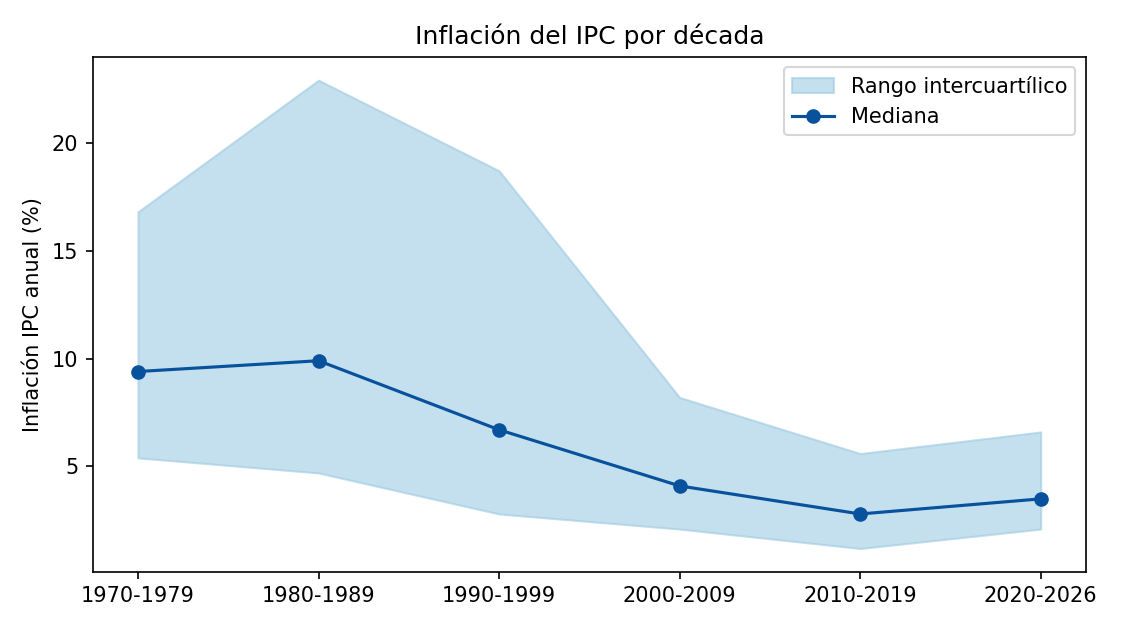

fig1_H1_mae_por_horizonte.png


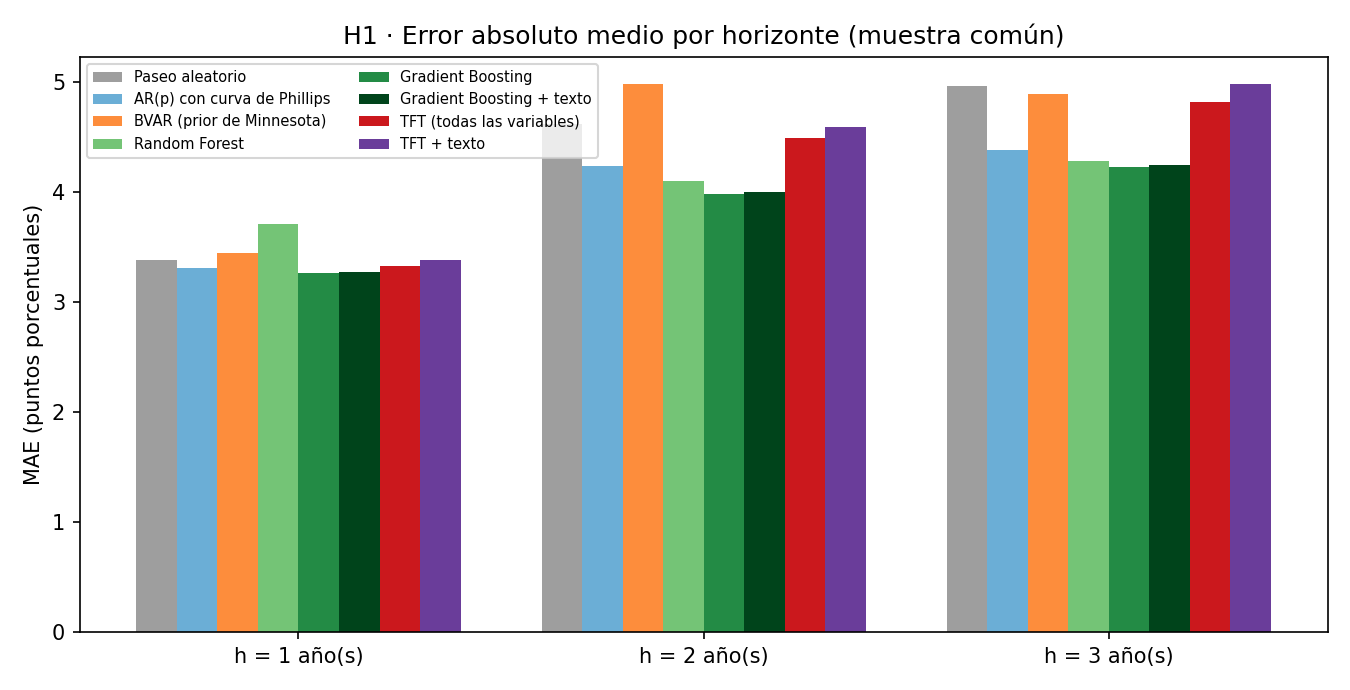

fig2_H1_mae_relativo.png


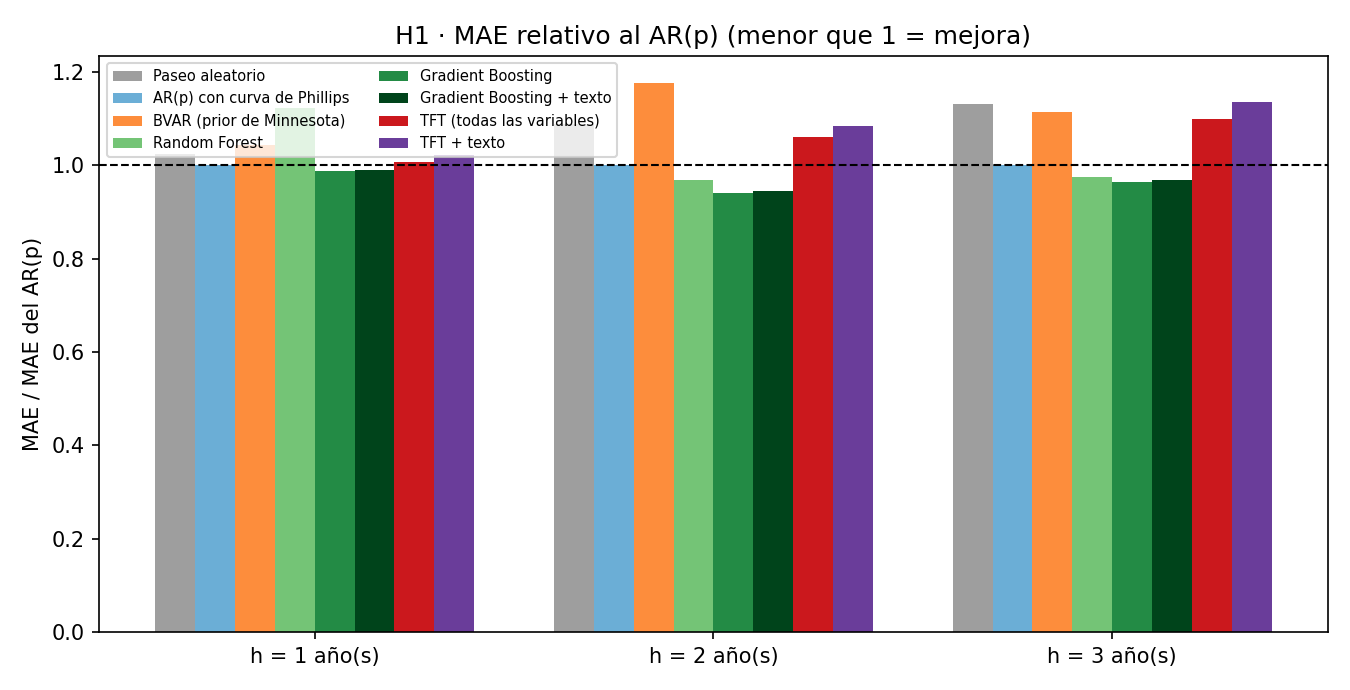

fig3_cobertura.png


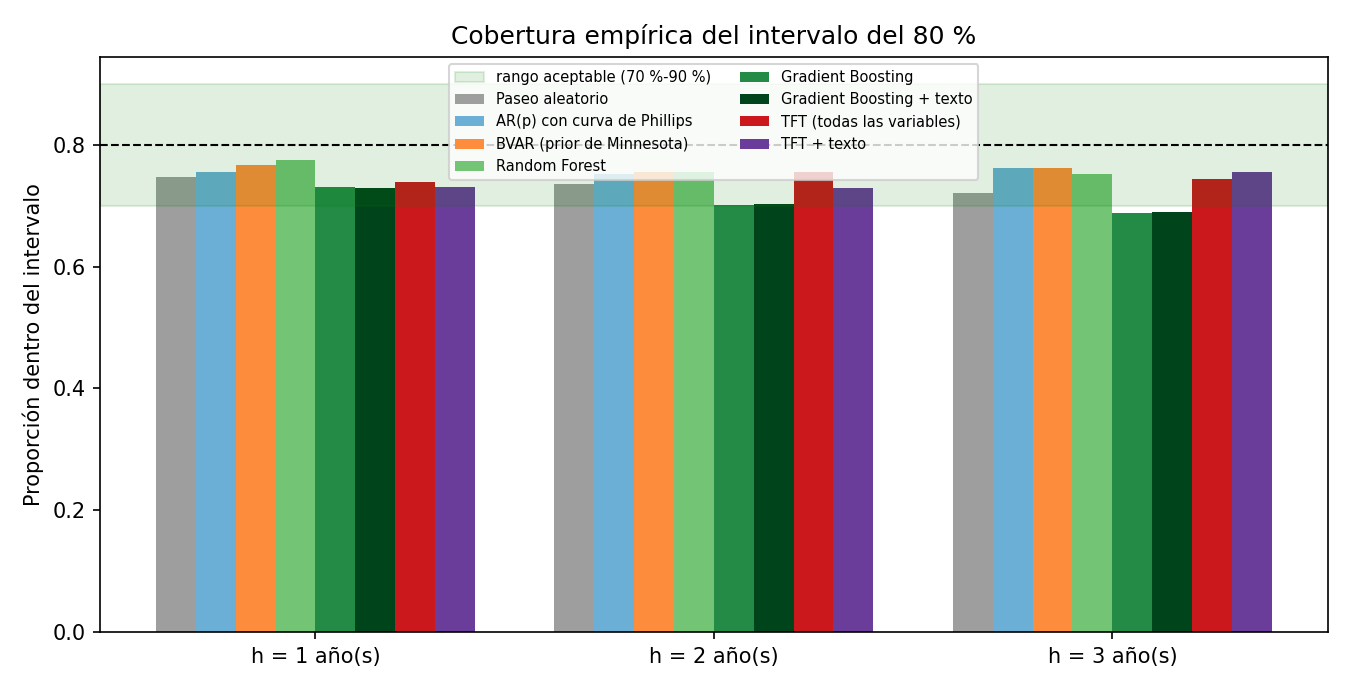

fig4_H2_efecto_texto.png


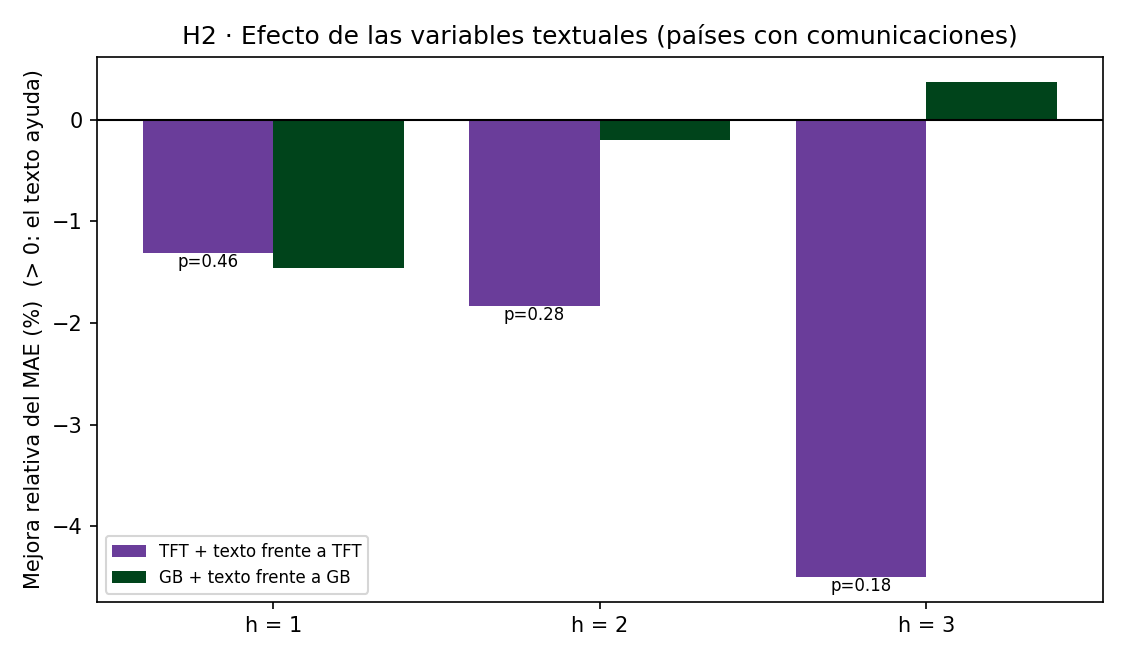

fig5_H3_importancia_variables.png


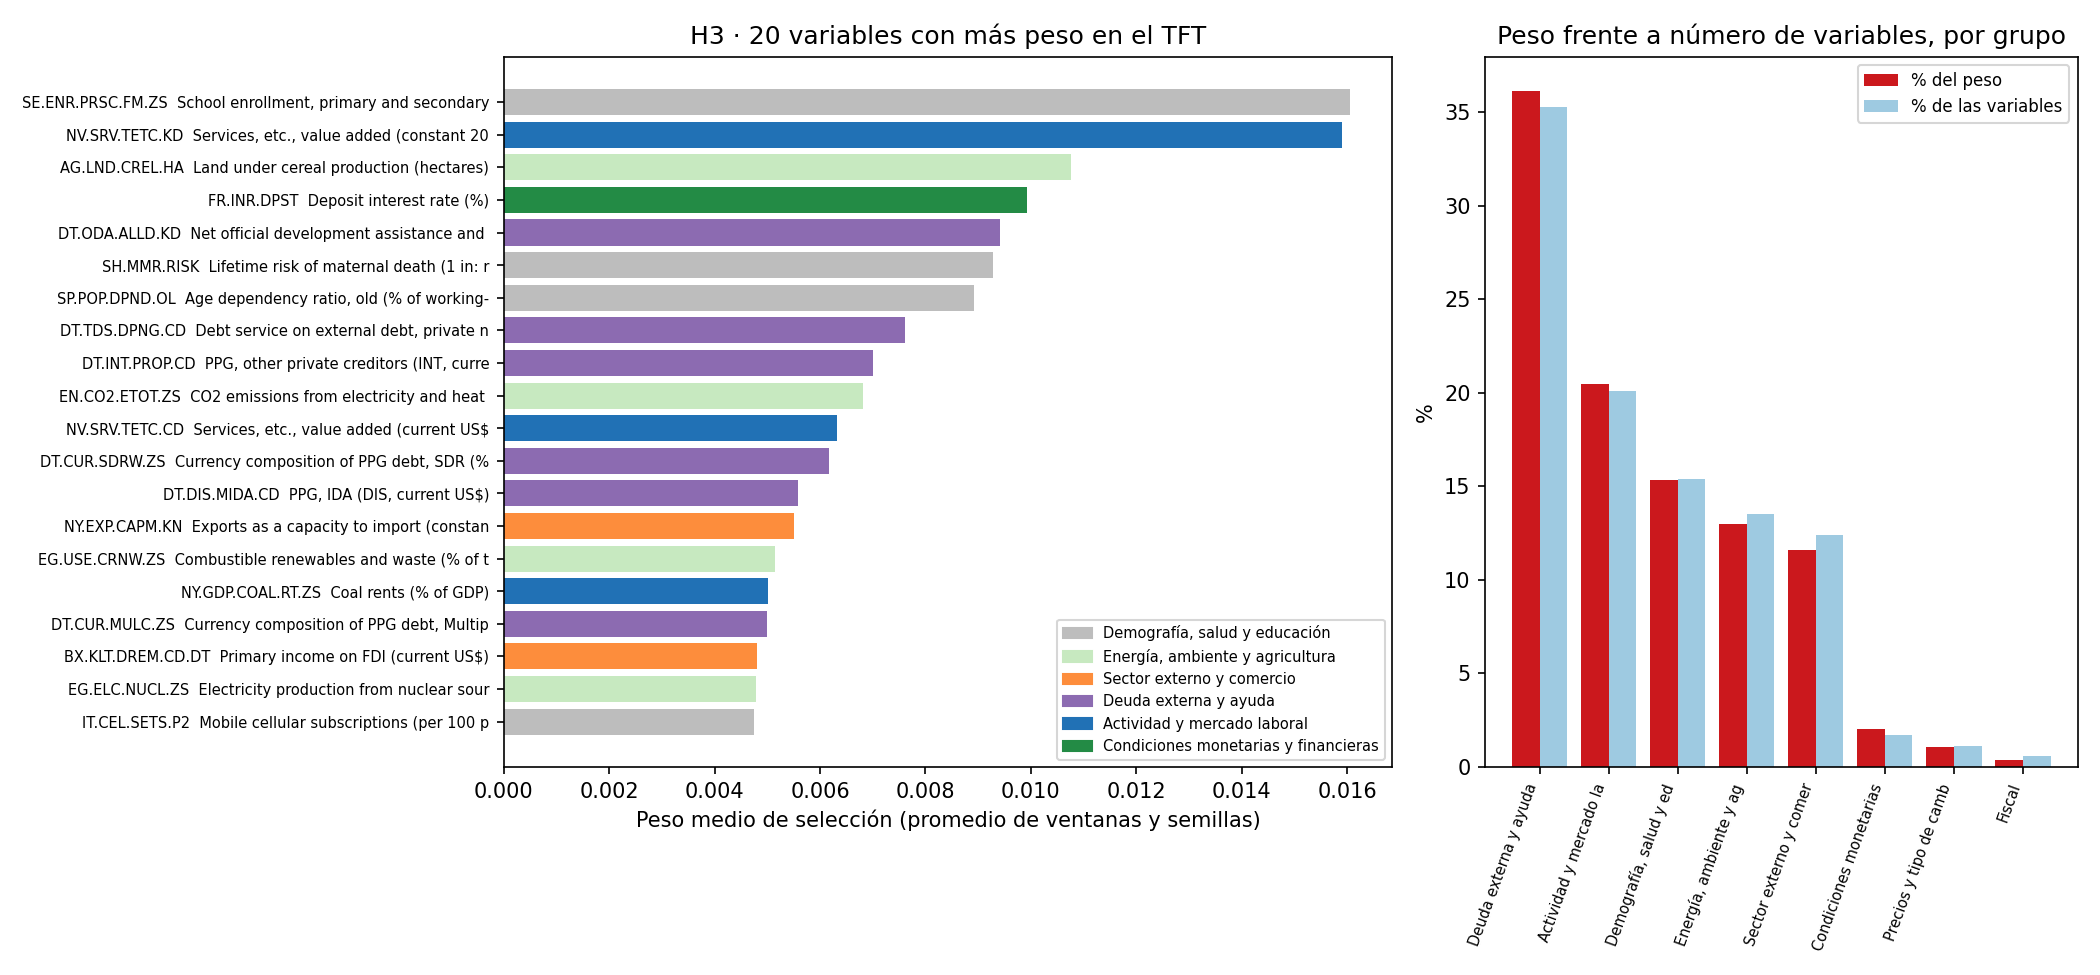

fig6_H3_estabilidad_ventanas.png


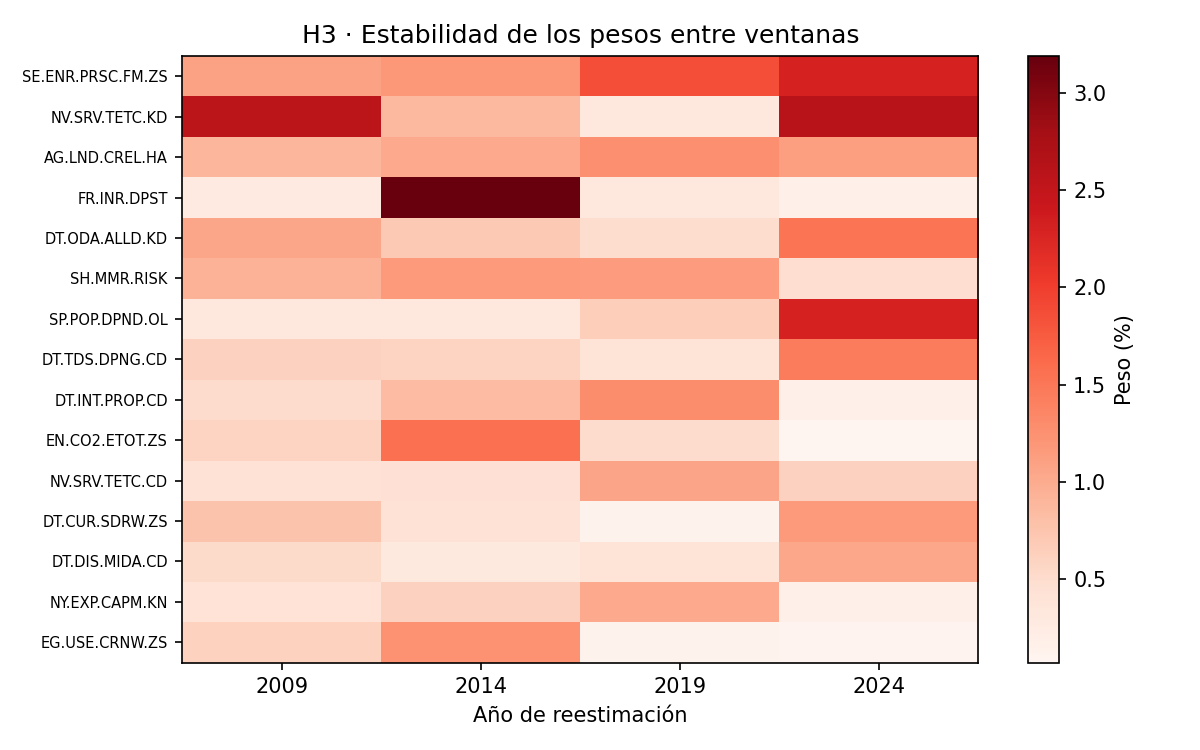

fig7_error_por_anio.png


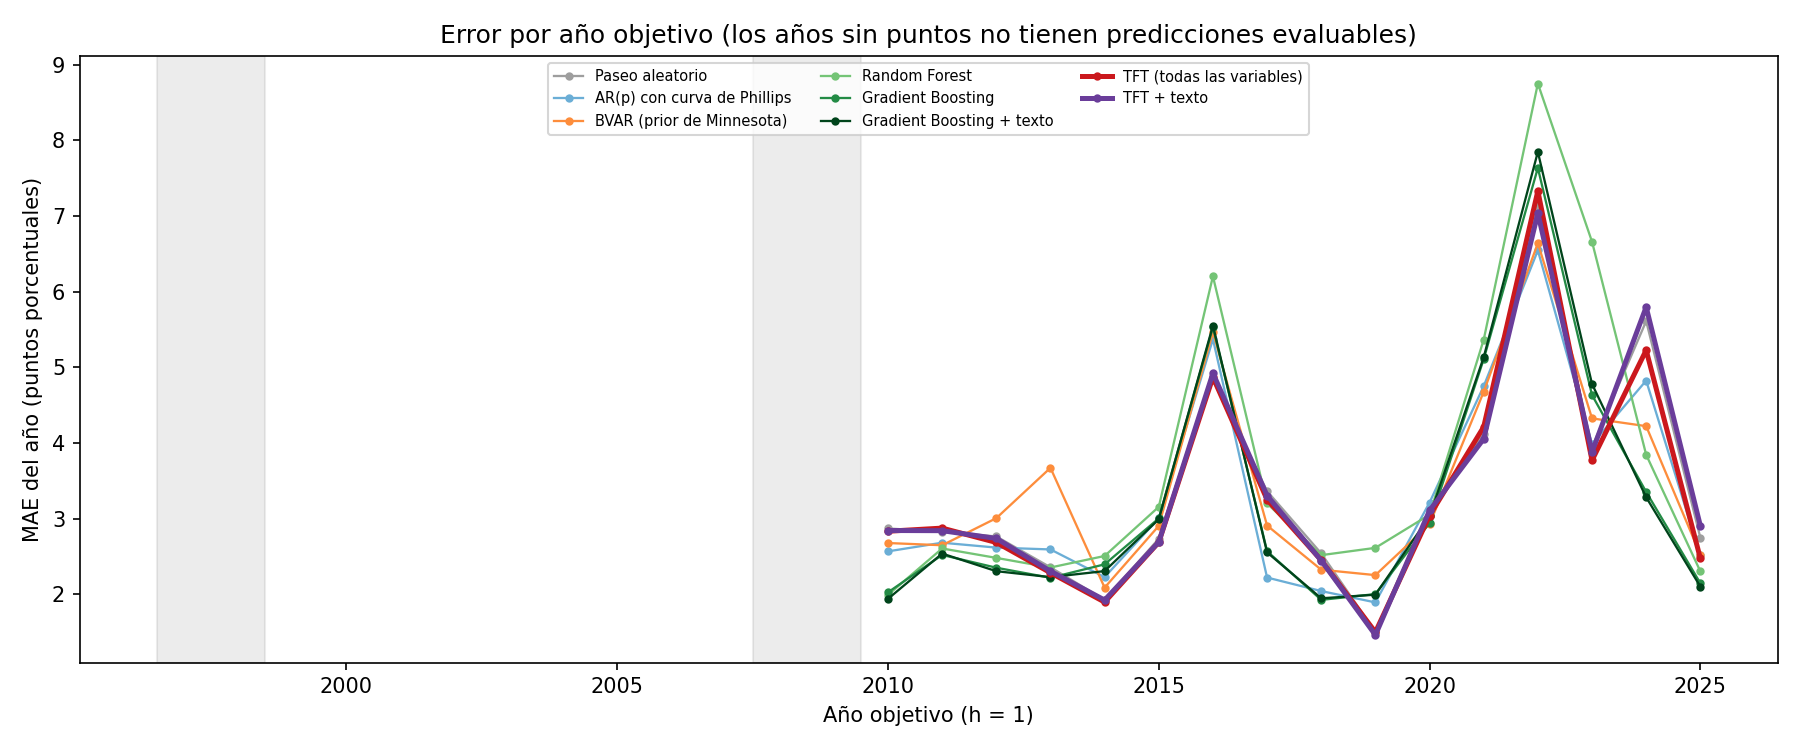

fig8_real_vs_predicho_tft.png


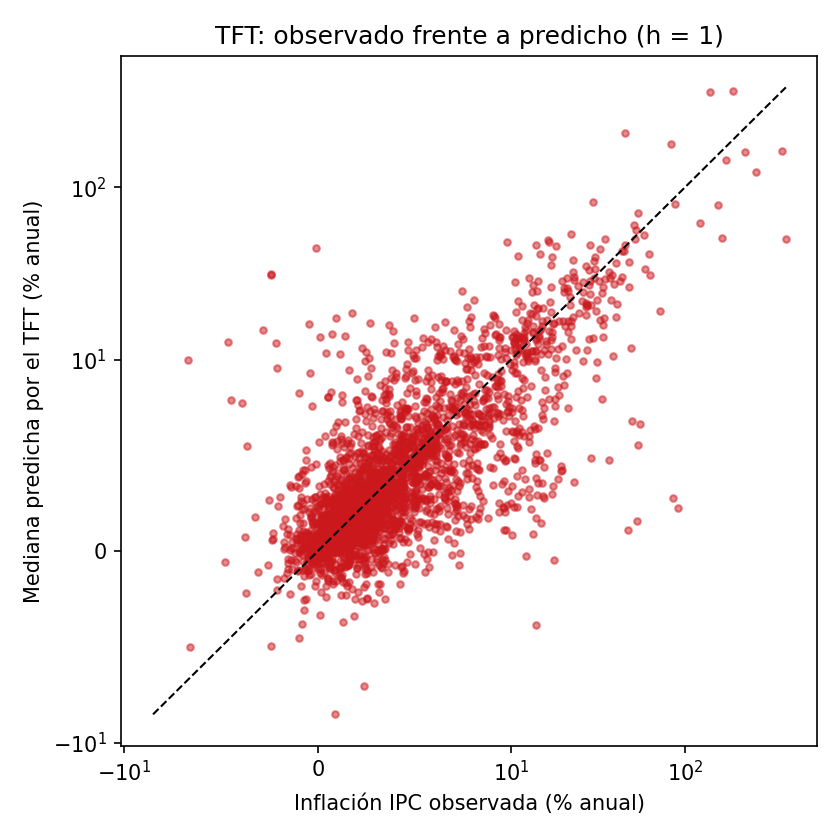

In [ ]:
mostrar(SALIDA)

## Fase 3 — Sensibilidad (opcional, solo con  CPU, segundos)
Repite la evaluación sin reentrenar nada: (a) puntuando también contra los datos de inflación **estimados** por modelo y (b) excluyendo el BVAR de la muestra común.

In [ ]:
ESTADO["Sensibilidad con objetivos estimados"] = ejecutar("--stage", "eval", "--score_imputed", "--tag", "_con_estimados", out=SALIDA)
ESTADO["Sensibilidad sin BVAR"] = ejecutar("--stage", "eval", "--common_exclude", "BVAR", "--tag", "_sin_BVAR", out=SALIDA)
for etiqueta in ("_con_estimados", "_sin_BVAR"):
    f = f"{SALIDA}/hipotesis_resumen{etiqueta}.json"
    if os.path.isfile(f):
        r = json.load(open(f, encoding="utf-8"))
        print(etiqueta, "->", {h: r[h]["veredicto"] for h in ("H1", "H2", "H3")})

Log: /content/drive/MyDrive/TFM/resultados_v3/logs/20261030_031516.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Base leída desde la copia rápida (10,032 filas).
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).

== PASO 2/6: Análisis exploratorio ==

== PASO 3/6: Construcción del panel ==
   Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.
   Variables explicativas: 531 | variables textuales: 18 | economías: 176 (16 con comunicaciones) | observaciones con inflación: 10,032

== PASO 5/6: Evaluación fuera de muestra ==
   Muestra común, métricas, contrastes de panel, MCS y las tres hipótesis.
   Puntuación incluyendo objetivos estimados (sensibilidad).
   Modelos: RW, AR, BVAR, RF, GB, GB_TXT, TFT, TFT_TXT | muestra común definida por: RW, AR, BVAR, RF, G

## Fase 4 — Pronóstico ligero hasta 2028

In [ ]:
ESTADO["Pronóstico 2028"] = ejecutar("--stage", "forecast", "--forecast_until", 2028, out=SALIDA)
f = f"{SALIDA}/pronosticos_2028/pronosticos_futuros_2028.csv"
if os.path.isfile(f):
    display(pd.read_csv(f).head(12)); print("Archivo completo:", f)

Log: /content/drive/MyDrive/TFM/resultados_v3/logs/20261030_031559.log

== PASO 1/6: Lectura de la base y de las comunicaciones ==
   Se unen las dos partes del Excel y se calculan las variables textuales (BERT + léxico).
   Base leída desde la copia rápida (10,032 filas).
   Panel: 176 economías, 1970-2026, 531 indicadores, 10,032 observaciones del objetivo.
   Variables textuales ya calculadas (copia rápida).

== PASO 2/6: Análisis exploratorio ==

== PASO 3/6: Construcción del panel ==
   Todas las variables de la base, rejilla país x año, inflación en asinh y rezagos.
   Variables explicativas: 531 | variables textuales: 18 | economías: 176 (16 con comunicaciones) | observaciones con inflación: 10,032
Pronóstico ligero guardado. Son proyecciones sin métricas de evaluación.
Duración: 0.2 min | código de salida: 0


,model,country,origin_year,target_year,horizon,q10,q50,q90,status
0,RW,ABW,2026,2027,1,0.454699,1.803066,4.674096,pronostico_futuro_no_evaluado
1,AR2_pooled,ABW,2026,2027,1,0.460906,1.979626,4.780548,pronostico_futuro_no_evaluado
2,RW,ABW,2026,2028,2,0.063394,1.804337,6.814684,pronostico_futuro_no_evaluado
3,AR2_pooled,ABW,2026,2028,2,0.266863,2.539386,8.538856,pronostico_futuro_no_evaluado
4,RW,AFG,2026,2027,1,2.161666,5.608471,13.809132,pronostico_futuro_no_evaluado
5,AR2_pooled,AFG,2026,2027,1,1.940088,5.494242,12.734603,pronostico_futuro_no_evaluado
6,RW,AFG,2026,2028,2,1.397800,5.611983,20.028347,pronostico_futuro_no_evaluado
7,AR2_pooled,AFG,2026,2028,2,1.248262,5.718858,18.728382,pronostico_futuro_no_evaluado
8,RW,AGO,2026,2027,1,4.217291,10.615854,26.015594,pronostico_futuro_no_evaluado
9,AR2_pooled,AGO,2026,2027,1,3.923357,10.688178,24.652739,pronostico_futuro_no_evaluado


Archivo completo: /content/drive/MyDrive/TFM/resultados_v3/pronosticos_2028/pronosticos_futuros_2028.csv


## Fase 5 — Resumen final

In [ ]:
estados = pd.DataFrame([{"Proceso": k, "Código": v, "Estado": "Correcto" if v == 0 else "Revisar log y volver a ejecutar (se reanuda)"} for k, v in ESTADO.items()])
display(estados)

ruta_json = f"{SALIDA}/hipotesis_resumen.json"
assert os.path.isfile(ruta_json), "Falta la evaluación: ejecuta la etapa 4."
hip = json.load(open(ruta_json, encoding="utf-8"))
enun = {"H1": "El TFT reduce el error de predicción respecto a los modelos de referencia, de forma significativa",
        "H2": "La inclusión de variables textuales mejora el desempeño, especialmente en horizontes largos",
        "H3": "Los pesos de selección de variables son estables y económicamente interpretables (precios, actividad, condiciones monetarias)"}
resumen = pd.DataFrame([{"Hipótesis": h, "Enunciado": enun[h], "Veredicto": hip[h]["veredicto"]} for h in ("H1", "H2", "H3")])
display(resumen)
print("Las tres hipótesis fueron contrastadas con los datos de la corrida completa.")
display(Markdown(open(f"{SALIDA}/lectura_resultados.md", encoding="utf-8").read()))
print("\nArchivos principales en", SALIDA)
for f in ("tablas_tfm.xlsx", "lectura_resultados.md", "hipotesis_resumen.json", "muestra_comun.csv"):
    print(" -", f, "OK" if os.path.isfile(f"{SALIDA}/{f}") else "no encontrado")
print(" - figuras:", len(glob.glob(f"{SALIDA}/figuras/*.png")), "PNG")

,Proceso,Código,Estado
0,Prueba rápida,0,Correcto
1,Etapa 1: datos y texto,0,Correcto
2,Etapa 2: modelos de referencia,0,Correcto
3,Etapa 3: TFT,0,Correcto
4,Etapa 4: evaluación,0,Correcto
5,Sensibilidad con objetivos estimados,0,Correcto
6,Sensibilidad sin BVAR,0,Correcto
7,Pronóstico 2028,0,Correcto


,Hipótesis,Enunciado,Veredicto
0,H1,El TFT reduce el error de predicción respecto ...,NO RESPALDADA
1,H2,La inclusión de variables textuales mejora el ...,NO RESPALDADA
2,H3,Los pesos de selección de variables son establ...,PARCIALMENTE RESPALDADA


Las tres hipótesis fueron contrastadas con los datos de la corrida completa.


# Lectura de resultados: tres hipótesis del TFM

Muestra común: h=1: 2758 obs., h=2: 2582 obs., h=3: 2406 obs.. Los objetivos de inflación estimados por modelo (no publicados) no se usan para puntuar.

## H1 · El TFT reduce el error frente a los modelos de referencia, de forma significativa: **NO RESPALDADA**
- MAE del TFT relativo al AR(p): h=1: 1.006, h=2: 1.061, h=3: 1.100 (criterio 1, <1 en al menos 2 horizontes: no).
- Significativamente mejor (Diebold-Mariano de panel, errores agrupados por país y año, 5 %) que AR(p) con curva de Phillips y BVAR (prior de Minnesota) en al menos 2 horizontes: no.
- TFT dentro del conjunto de confianza del modelo (90 %) en al menos 2 horizontes: sí.
- Referencias superadas de forma significativa (de 5): h=1: 0, h=2: 0, h=3: 0.
- Menor MAE en la muestra común: h=1: Gradient Boosting, h=2: Gradient Boosting, h=3: Gradient Boosting.

## H2 · Las variables textuales mejoran el desempeño, sobre todo en horizontes largos: **NO RESPALDADA**
- Mejora relativa del MAE del TFT + texto frente al TFT numérico (países con comunicaciones; > 0 = ayuda): h=1: -1.31 % (p = 0.462, N = 255), h=2: -1.83 % (p = 0.278, N = 239), h=3: -4.50 % (p = 0.176, N = 223).
- Mejora en al menos 2 horizontes: no; significativa al 10 % en algún horizonte: no; mayor en el horizonte largo que en el corto: no.
- Comprobación con otro modelo (GB + texto frente a GB): h=1: -1.45 %, h=2: -0.20 %, h=3: +0.38 %.
- Panel completo (el texto solo existe para algunos países): h=1: -1.58 %, h=2: -2.27 %, h=3: -3.28 %.
- Peso que el TFT + texto asigna al bloque textual: 3.7% (las variables textuales son el 3.3% del total). Principales: TXT_has_text (0.0058), TXT_pc7 (0.0039), TXT_pc3 (0.0033), TXT_estabilidad_fin (0.0029), TXT_incertidumbre (0.0028).

## H3 · Pesos de selección estables y económicamente interpretables: **PARCIALMENTE RESPALDADA**
- Estabilidad entre ventanas de reestimación (2009, 2014, 2019, 2024): Spearman medio 0.59 (umbral 0,50); solape top-20 6.3 de 20 (azar 0.8; umbral 5); solape top-10 3.5 de 10 (azar 0.2). Estable: sí.
- Estabilidad entre semillas dentro de cada ventana: Spearman medio 0.05.
- Interpretación económica: 4 de las 20 variables principales y 24% del peso del top-20 corresponden a precios, actividad y condiciones monetarias (esos grupos son el 23% de las variables; enriquecimiento 1.05x; umbral: ≥ 40 % del peso y enriquecimiento ≥ 1,5). Interpretable: no.
- Las importancias son descriptivas, no causales.

## Calibración del intervalo del 80 % (criterio: entre 70 % y 90 %), h = 1
- Paseo aleatorio: 74.7 % (calibrado)
- AR(p) con curva de Phillips: 75.6 % (calibrado)
- BVAR (prior de Minnesota): 76.6 % (calibrado)
- Random Forest: 77.5 % (calibrado)
- Gradient Boosting: 73.2 % (calibrado)
- Gradient Boosting + texto: 72.9 % (calibrado)
- TFT (todas las variables): 73.9 % (calibrado)
- TFT + texto: 73.1 % (calibrado)

## Cautelas que acompañan estos resultados
- Reestimación en 2009, 2014, 2019 y 2024 con ventana expansiva; hiperparámetros fijados sin búsqueda exhaustiva.
- Entre 2015 y 2026 la mayoría de los indicadores de la base son proyecciones (382 de 531 repiten el valor de 2014): la información explicativa de las ventanas recientes es limitada para todos los modelos.
- Las comunicaciones de bancos centrales cubren 16 economías de la base (ARG no está en la base); en el resto, las variables textuales valen 0 y se señalan con TXT_has_text.
- Los contrastes de significación usan errores agrupados por país y por año objetivo; con pocos años la potencia es limitada.


Archivos principales en /content/drive/MyDrive/TFM/resultados_v3
 - tablas_tfm.xlsx OK
 - lectura_resultados.md OK
 - hipotesis_resumen.json OK
 - muestra_comun.csv OK
 - figuras: 9 PNG
